<a href="https://colab.research.google.com/github/JulTob/Optimization/blob/main/Practicas/Practica_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <font color="steelblue">**Enunciado  Práctica 3**</font>

## <font color="steelblue">**Isotonic Regression**</font>

La <b>regresión isotónica</b> es una técnica no paramétrica utilizada en estadística para ajustar un conjunto de datos/observaciones a una función no decreciente. Esta técnica es útil cuando se espera que la relación entre las variables independientes y la variable dependiente  es una relación monótona pero no lineal.

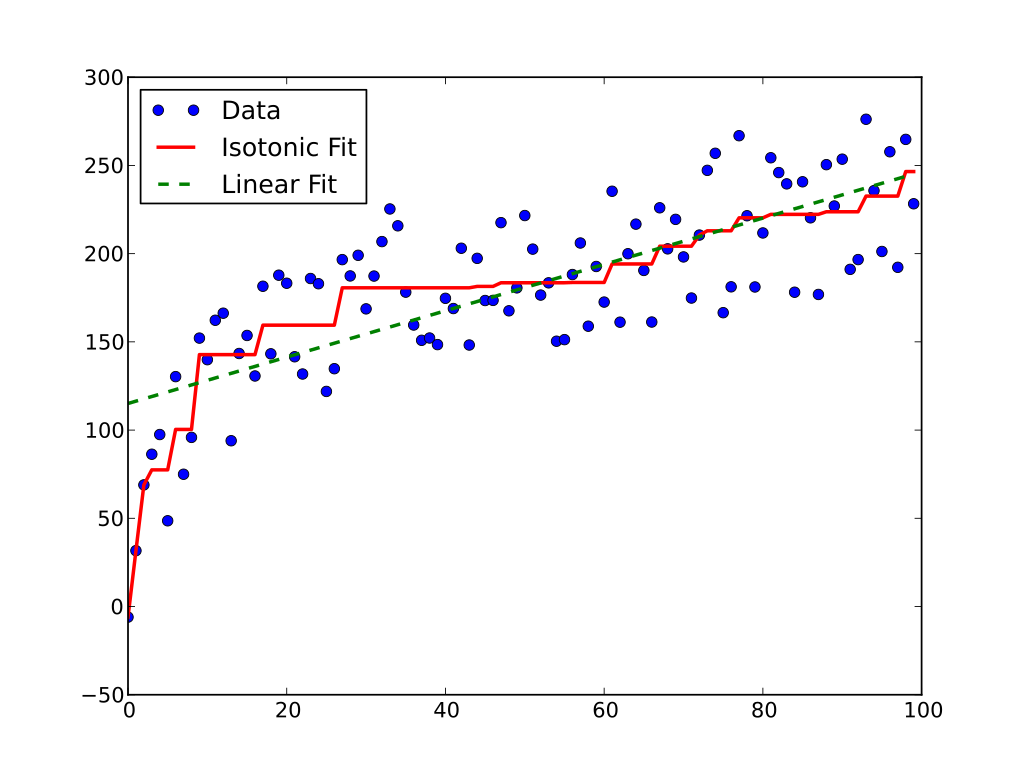

Dado un conjunto de observaciones $(x_i,y_i)$ para $i=1,\cdots,n$, la regressión isotónica puede formularse mediante un problema de optimización cuadrática del siguiente modo:

$$\min \sum_{i=1}^n \epsilon^2_i \qquad \qquad\qquad$$
$$ s.a. \qquad\qquad\qquad\qquad$$
$$  y_i=\alpha_i + \epsilon_i, \quad i=1,\cdots,n$$
$$ p_{ij} \alpha_i \leq p_{ij}\alpha_j, \quad i,j=1,\cdots,n$$
$$ \alpha_i, \, \,\epsilon_i \,\quad  \text{free} \quad i=1,\cdots,n$$

donde $P=\{p_{ij}\}$ es una matriz binaria que recoge el orden parcial de los datos observados $x_i$.

$$ p_{ij}= 1 \quad si \quad  \mathbf{x}_i \preceq \mathbf{x}_j$$
$$ p_{ij}= 0 \quad si \quad  \mathbf{x}_i \nprec \mathbf{x}_j$$

## <font color="steelblue">**Ejercicio  Práctica 3**</font>

Para cada una de las distribuciones siguientes, gererar 25 valores y calcular la regresión isotónica para esos 25 valores.
* Caso 1: Cobb-Douglas, ($x,y$):
  $$y_i=x_i^{0.5}+v_i, \quad x_i \sim U(1,6), v_i\sim N(0,\sigma_v^2)$$
* Caso 2: Logistic function, ($x,y$):
  $$y_i=\frac{1+e^7}{e^7}\frac{e^{-3+10x_i}}{1+e^{-3+10x_i}}+v_i, \quad x_i \sim U(0,1), v_i\sim N(0,\sigma_v^2)$$

Utilizar $\sigma_v= 0.1$ y $\sigma_v= 0.2$

* Realizar una representación gráfica del ajuste realizado en los casos 1 y 2.
* Calcular para cada ajuste

  $$ MSE = \dfrac{1}{n}\sum_{i}( \hat{y}_i - y_i)^2$$

* Comparar con los siguientes ajustes de regresión:
  - $ \hat{y} = \alpha + \beta x $
  - $ \hat{y} = \alpha + \beta_1 x + \beta_2 x^2 $
  - $ \hat{y} = \alpha + \beta_1 x + \beta_2 x^2 +\beta_3 x^3$
  - $ \hat{y} = \alpha x^\beta $

y otras funciones que te apetezcan

  


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
from scipy.optimize import curve_fit

# Fijar semilla para reproducibilidad
np.random.seed(42)

# 1. Generación de datos
def generar_datos_caso1(n=25, sigma=0.1):
    x = np.random.uniform(1, 6, n)
    v = np.random.normal(0, sigma, n)
    y = x**0.5 + v
    return x, y

def generar_datos_caso2(n=25, sigma=0.1):
    x = np.random.uniform(0, 1, n)
    v = np.random.normal(0, sigma, n)
    factor1 = (1 + np.exp(7)) / np.exp(7)
    factor2 = np.exp(-3 + 10*x) / (1 + np.exp(-3 + 10*x))
    y = factor1 * factor2 + v
    return x, y

In [2]:
def resolver_regresion_isotonica(x, y):
    """
    Resuelve la regresión isotónica formulada como un problema de optimización cuadrática:
    Minimizar sum (alpha_i - y_i)^2
    Sujeto a: alpha_i <= alpha_j para todo x_i <= x_j
    """
    n = len(x)
    alpha = cp.Variable(n)

    # Crear las restricciones de orden basados en los valores de x
    constraints = []
    for i in range(n):
        for j in range(n):
            if x[i] < x[j]:
                constraints.append(alpha[i] <= alpha[j])
            elif x[i] == x[j] and i != j:
                constraints.append(alpha[i] == alpha[j])

    # Función objetivo: Minimizar el error cuadrático
    objective = cp.Minimize(cp.sum_squares(alpha - y))
    prob = cp.Problem(objective, constraints)
    prob.solve()

    return alpha.value

In [3]:
# Definición de modelos para comparar
def modelo_lineal(x, a, b):
    return a + b * x

def modelo_cuadratico(x, a, b1, b2):
    return a + b1 * x + b2 * (x**2)

def modelo_cubico(x, a, b1, b2, b3):
    return a + b1 * x + b2 * (x**2) + b3 * (x**3)

def modelo_potencial(x, a, b):
    return a * (x**b)

def calcular_mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

def ajustar_y_evaluar(x, y, nombre_caso):
    # Regresión Isotónica (QP)
    y_iso = resolver_regresion_isotonica(x, y)

    # Ajustes paramétricos
    popt_lin, _ = curve_fit(modelo_lineal, x, y)
    popt_quad, _ = curve_fit(modelo_cuadratico, x, y)
    popt_cub, _ = curve_fit(modelo_cubico, x, y)

    # Para el modelo potencial, evitamos valores negativos o cero en x si fuera necesario
    try:
        popt_pot, _ = curve_fit(modelo_potencial, x, y, p0=[1, 1])
        y_pot = modelo_potencial(x, *popt_pot)
    except:
        y_pot = np.nan * np.ones_like(y)

    y_lin = modelo_lineal(x, *popt_lin)
    y_quad = modelo_cuadratico(x, *popt_quad)
    y_cub = modelo_cubico(x, *popt_cub)

    # Calcular MSEs
    mses = {
        'Isotónica (QP)': calcular_mse(y, y_iso),
        'Lineal': calcular_mse(y, y_lin),
        'Cuadrática': calcular_mse(y, y_quad),
        'Cúbica': calcular_mse(y, y_cub),
        'Potencial': calcular_mse(y, y_pot) if not np.isnan(y_pot[0]) else np.nan
    }

    # Representación Gráfica
    x_grid = np.linspace(min(x), max(x), 200)

    plt.figure(figsize=(10, 6))
    plt.scatter(x, y, color='black', zorder=5, label='Datos Observados')

    # Para la isotónica, ordenamos para mostrar el gráfico en escalera/monótono de forma correcta
    sort_idx = np.argsort(x)
    plt.step(x[sort_idx], y_iso[sort_idx], where='post', color='red', linewidth=2, label='Regresión Isotónica')

    plt.plot(x_grid, modelo_lineal(x_grid, *popt_lin), '--', label='Lineal')
    plt.plot(x_grid, modelo_cuadratico(x_grid, *popt_quad), '--', label='Cuadrática')
    plt.plot(x_grid, modelo_cubico(x_grid, *popt_cub), '--', label='Cúbica')
    if not np.isnan(y_pot[0]):
        plt.plot(x_grid, modelo_potencial(x_grid, *popt_pot), '--', label='Potencial')

    plt.title(f'Ajustes de Regresión - {nombre_caso}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    return mses

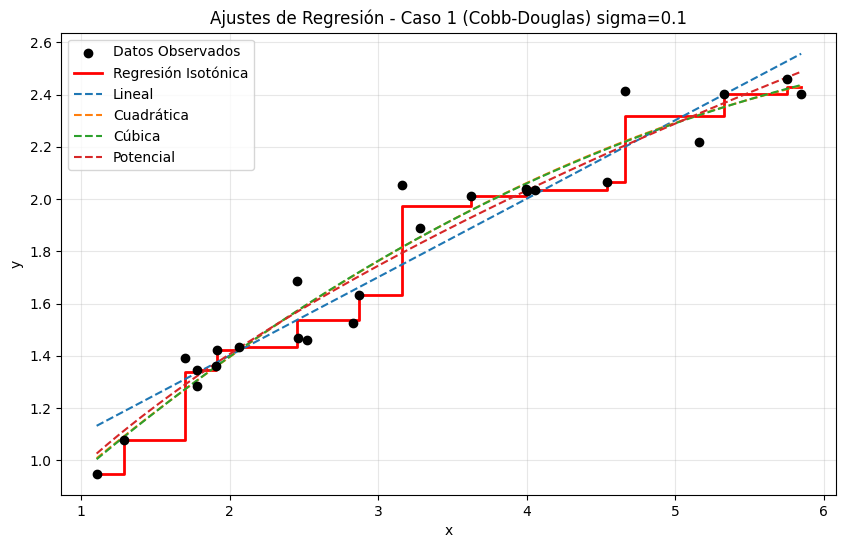

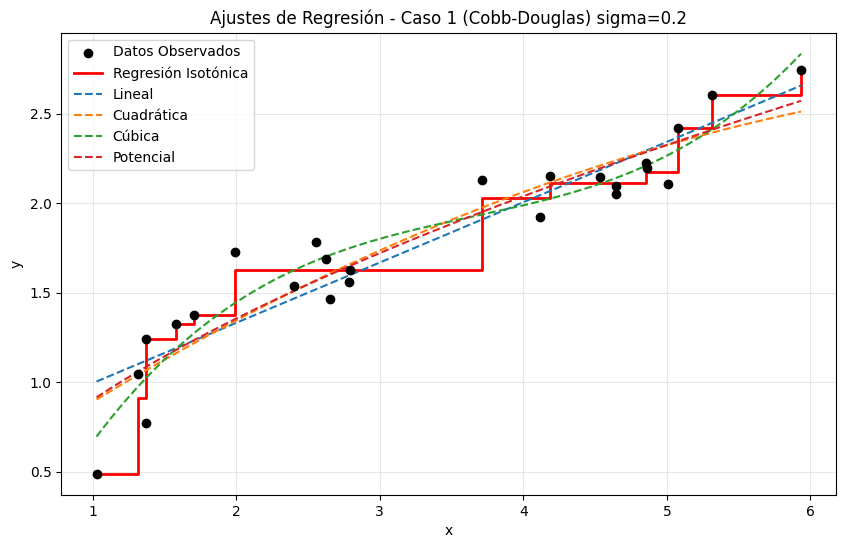

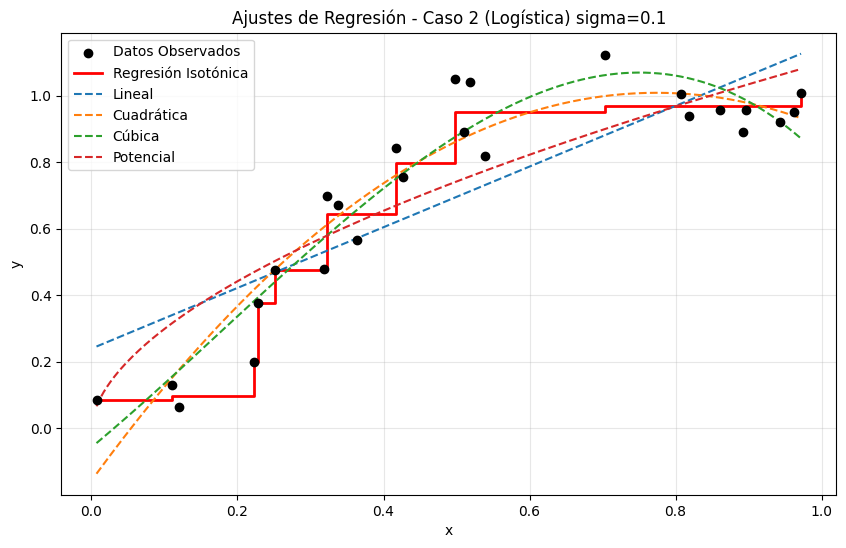

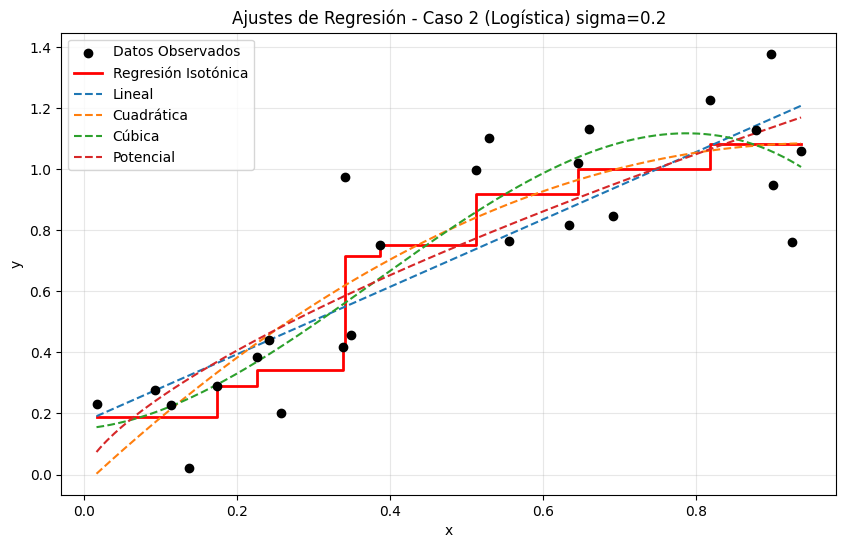

,Isotónica (QP),Lineal,Cuadrática,Cúbica,Potencial
Caso 1 (Cobb-Douglas) sigma=0.1,0.002945,0.013427,0.009687,0.009684,0.010100
Caso 1 (Cobb-Douglas) sigma=0.2,0.005875,0.036936,0.033963,0.022068,0.032190
Caso 2 (Logística) sigma=0.1,0.003577,0.031121,0.010404,0.009005,0.022997
Caso 2 (Logística) sigma=0.2,0.022080,0.039864,0.032602,0.029040,0.037191


In [4]:
# Ejecutar experimentos para todos los casos y sigmas
resultados = {}

casos = [
    ("Caso 1 (Cobb-Douglas) sigma=0.1", generar_datos_caso1, 0.1),
    ("Caso 1 (Cobb-Douglas) sigma=0.2", generar_datos_caso1, 0.2),
    ("Caso 2 (Logística) sigma=0.1", generar_datos_caso2, 0.1),
    ("Caso 2 (Logística) sigma=0.2", generar_datos_caso2, 0.2),
]

for nombre, generador, sigma in casos:
    x, y = generador(n=25, sigma=sigma)
    mses = ajustar_y_evaluar(x, y, nombre)
    resultados[nombre] = mses

# Mostrar tabla comparativa de MSE
df_resultados = pd.DataFrame(resultados).T
display(df_resultados)

### Comparación Adicional con el Modelo Logístico (Logit)

In [5]:
def modelo_logistico(x, L, k, x0, c):
    return L / (1 + np.exp(-k * (x - x0))) + c

def ajustar_y_evaluar_con_logit(x, y, nombre_caso):
    # Regresión Isotónica (QP)
    y_iso = resolver_regresion_isotonica(x, y)

    # Ajustes paramétricos existentes
    popt_lin, _ = curve_fit(modelo_lineal, x, y)
    popt_quad, _ = curve_fit(modelo_cuadratico, x, y)
    popt_cub, _ = curve_fit(modelo_cubico, x, y)

    try:
        popt_pot, _ = curve_fit(modelo_potencial, x, y, p0=[1, 1])
        y_pot = modelo_potencial(x, *popt_pot)
    except:
        y_pot = np.nan * np.ones_like(y)

    # Ajuste del modelo Logístico (Logit)
    # p0 aproximado: L=1, k=10, x0=0.5, c=0
    try:
        popt_log, _ = curve_fit(modelo_logistico, x, y, p0=[1, 10, 0.5, 0], maxfev=10000)
        y_log = modelo_logistico(x, *popt_log)
    except Exception as e:
        popt_log = None
        y_log = np.nan * np.ones_like(y)

    y_lin = modelo_lineal(x, *popt_lin)
    y_quad = modelo_cuadratico(x, *popt_quad)
    y_cub = modelo_cubico(x, *popt_cub)

    # Calcular MSEs
    mses = {
        'Isotónica (QP)': calcular_mse(y, y_iso),
        'Lineal': calcular_mse(y, y_lin),
        'Cuadrática': calcular_mse(y, y_quad),
        'Cúbica': calcular_mse(y, y_cub),
        'Potencial': calcular_mse(y, y_pot) if not np.isnan(y_pot[0]) else np.nan,
        'Logístico (Logit)': calcular_mse(y, y_log) if popt_log is not None else np.nan
    }

    # Representación Gráfica
    x_grid = np.linspace(min(x), max(x), 200)

    plt.figure(figsize=(10, 6))
    plt.scatter(x, y, color='black', zorder=5, label='Datos Observados')

    sort_idx = np.argsort(x)
    plt.step(x[sort_idx], y_iso[sort_idx], where='post', color='red', linewidth=2.5, label='Regresión Isotónica')

    plt.plot(x_grid, modelo_lineal(x_grid, *popt_lin), '--', label='Lineal')
    plt.plot(x_grid, modelo_cuadratico(x_grid, *popt_quad), '--', label='Cuadrática')
    plt.plot(x_grid, modelo_cubico(x_grid, *popt_cub), '--', label='Cúbica')
    if not np.isnan(y_pot[0]):
        plt.plot(x_grid, modelo_potencial(x_grid, *popt_pot), '--', label='Potencial')
    if popt_log is not None:
        plt.plot(x_grid, modelo_logistico(x_grid, *popt_log), 'g-', linewidth=2, label='Logístico (Logit)')

    plt.title(f'Ajustes de Regresión (Incluyendo Logit) - {nombre_caso}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    return mses

/tmp/ipykernel_749/4124598016.py:2: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k * (x - x0))) + c


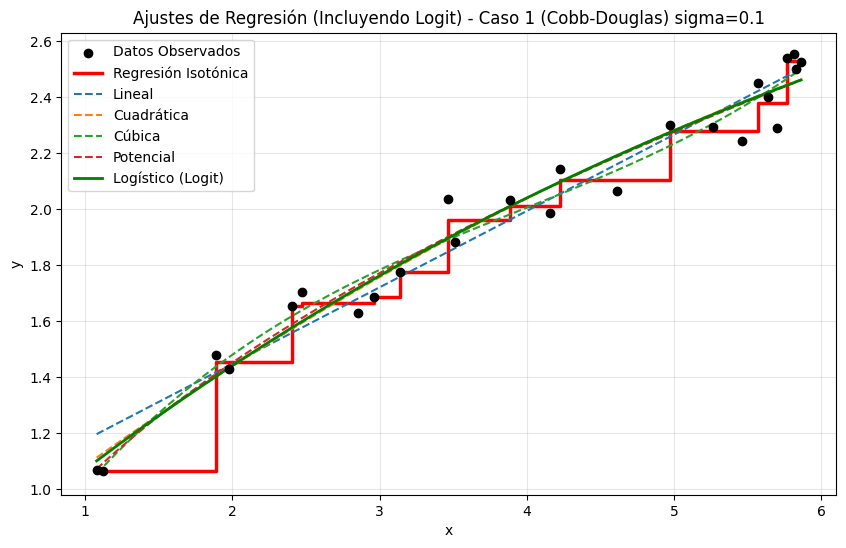

/tmp/ipykernel_749/4124598016.py:22: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_log, _ = curve_fit(modelo_logistico, x, y, p0=[1, 10, 0.5, 0], maxfev=10000)


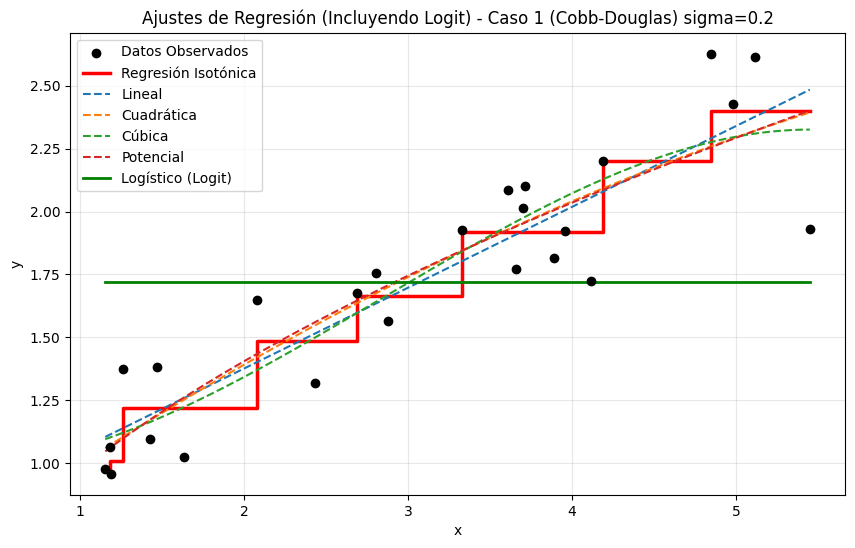

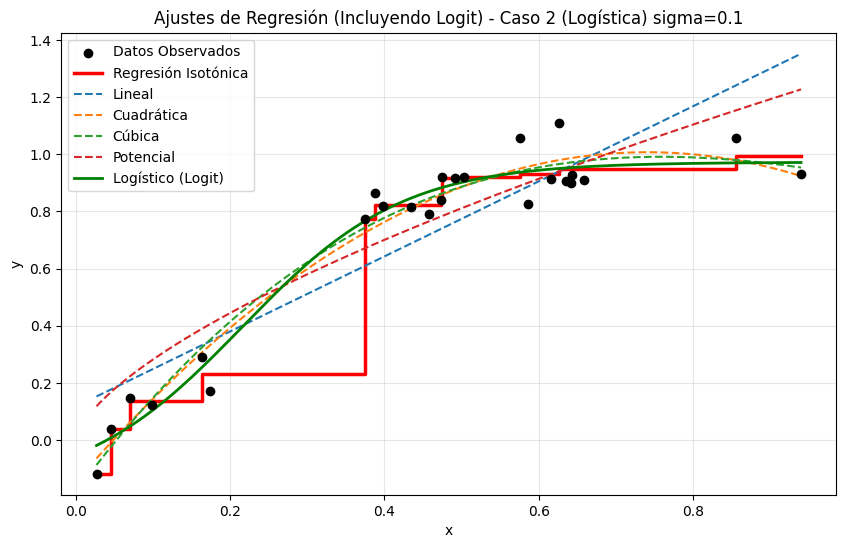

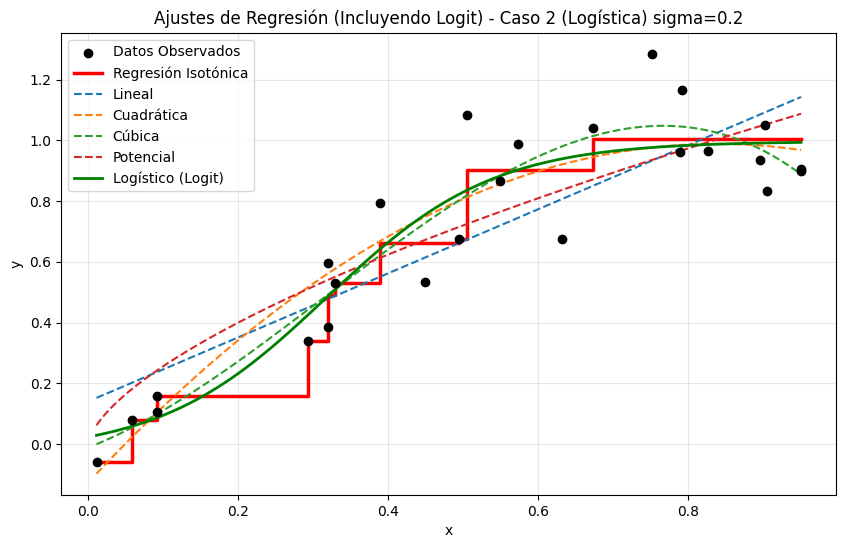

,Isotónica (QP),Lineal,Cuadrática,Cúbica,Potencial,Logístico (Logit)
Caso 1 (Cobb-Douglas) sigma=0.1,0.001476,0.007849,0.006426,0.005227,0.005980,0.006282
Caso 1 (Cobb-Douglas) sigma=0.2,0.025602,0.043060,0.041627,0.040689,0.041907,0.228446
Caso 2 (Logística) sigma=0.1,0.003099,0.026206,0.005851,0.005661,0.017782,0.004903
Caso 2 (Logística) sigma=0.2,0.012560,0.034212,0.018819,0.015967,0.027374,0.018360


In [6]:
resultados_con_logit = {}

for nombre, generador, sigma in casos:
    # Usamos los mismos generadores para mantener consistencia
    x_c, y_c = generador(n=25, sigma=sigma)
    mses = ajustar_y_evaluar_con_logit(x_c, y_c, nombre)
    resultados_con_logit[nombre] = mses

# Mostrar nueva tabla comparativa de MSE con el modelo Logit
df_resultados_logit = pd.DataFrame(resultados_con_logit).T
display(df_resultados_logit)

In [7]:
# Calcular el ranking de los métodos basado en el MSE (de menor a mayor error)
# Obtenemos los rangos individuales de cada método para cada fila (caso)
rankings = df_resultados_logit.rank(axis=1, ascending=True)

# Calculamos la posición media de cada método a lo largo de todos los casos
ranking_promedio = rankings.mean().sort_values()

# Creamos un DataFrame para presentar el ranking oficial
df_ranking_final = pd.DataFrame({
    'Posición': range(1, len(ranking_promedio) + 1),
    'Método': ranking_promedio.index,
    'Rango Medio (menor es mejor)': ranking_promedio.values
}).set_index('Posición')

print("Ranking General de Métodos (Basado en el rendimiento en todos los escenarios):")
display(df_ranking_final)

Ranking General de Métodos (Basado en el rendimiento en todos los escenarios):


,Método,Rango Medio (menor es mejor)
Posición,,
1,Isotónica (QP),1.00
2,Cúbica,2.25
3,Logístico (Logit),3.75
4,Cuadrática,4.00
5,Potencial,4.25
6,Lineal,5.75


### Nueva Estructura de Ranking: Casos Horizontales y Regresiones Verticales

In [8]:
# 1. Calculamos los rankings horizontalmente para cada caso (fila por fila)
df_rankings_casos = df_resultados_logit.rank(axis=1, ascending=True)

# 2. Transponemos la matriz para que las regresiones queden en el eje vertical (filas)
# y los casos en el eje horizontal (columnas)
df_ranking_horizontal = df_rankings_casos.T

# 3. Añadimos la columna del 'Ranking Medio' al final
df_ranking_horizontal['Ranking Medio'] = df_ranking_horizontal.mean(axis=1)

# 4. Ordenamos las filas según el Ranking Medio final (de mejor a peor)
df_ranking_horizontal = df_ranking_horizontal.sort_values(by='Ranking Medio')

# Mostramos el DataFrame resultante
print("Tabla de Ranking (Eje horizontal: Casos, Eje vertical: Métodos):")
display(df_ranking_horizontal)

Tabla de Ranking (Eje horizontal: Casos, Eje vertical: Métodos):


,Caso 1 (Cobb-Douglas) sigma=0.1,Caso 1 (Cobb-Douglas) sigma=0.2,Caso 2 (Logística) sigma=0.1,Caso 2 (Logística) sigma=0.2,Ranking Medio
Isotónica (QP),1.0,1.0,1.0,1.0,1.00
Cúbica,2.0,2.0,3.0,2.0,2.25
Logístico (Logit),4.0,6.0,2.0,3.0,3.75
Cuadrática,5.0,3.0,4.0,4.0,4.00
Potencial,3.0,4.0,5.0,5.0,4.25
Lineal,6.0,5.0,6.0,6.0,5.75


### Inclusión del Modelo Escalón Rampa Truncado

In [9]:
def modelo_escalon_rampa(x, m, c):
    # Señal rampa truncada con mínimo 0 y máximo 1
    rampa = m * (x - c)
    return np.clip(rampa, 0, 1)

def ajustar_y_evaluar_completo(x, y, nombre_caso):
    # Regresión Isotónica (QP)
    y_iso = resolver_regresion_isotonica(x, y)

    # Ajustes paramétricos
    popt_lin, _ = curve_fit(modelo_lineal, x, y)
    popt_quad, _ = curve_fit(modelo_cuadratico, x, y)
    popt_cub, _ = curve_fit(modelo_cubico, x, y)

    try:
        popt_pot, _ = curve_fit(modelo_potencial, x, y, p0=[1, 1])
        y_pot = modelo_potencial(x, *popt_pot)
    except:
        y_pot = np.nan * np.ones_like(y)

    try:
        popt_log, _ = curve_fit(modelo_logistico, x, y, p0=[1, 10, 0.5, 0], maxfev=10000)
        y_log = modelo_logistico(x, *popt_log)
    except:
        y_log = np.nan * np.ones_like(y)

    # Ajuste de la Rampa Truncada (Escalón Rampa)
    try:
        # Estimación inicial sensata: pendiente positiva (m=2) y corte en c=0.2
        popt_rampa, _ = curve_fit(modelo_escalon_rampa, x, y, p0=[2.0, 0.2], maxfev=10000)
        y_rampa = modelo_escalon_rampa(x, *popt_rampa)
    except:
        popt_rampa = None
        y_rampa = np.nan * np.ones_like(y)

    y_lin = modelo_lineal(x, *popt_lin)
    y_quad = modelo_cuadratico(x, *popt_quad)
    y_cub = modelo_cubico(x, *popt_cub)

    # Calcular MSEs
    mses = {
        'Isotónica (QP)': calcular_mse(y, y_iso),
        'Lineal': calcular_mse(y, y_lin),
        'Cuadrática': calcular_mse(y, y_quad),
        'Cúbica': calcular_mse(y, y_cub),
        'Potencial': calcular_mse(y, y_pot) if not np.isnan(y_pot[0]) else np.nan,
        'Logístico (Logit)': calcular_mse(y, y_log) if not np.isnan(y_log[0]) else np.nan,
        'Escalón Rampa': calcular_mse(y, y_rampa) if popt_rampa is not None else np.nan
    }

    # Representación Gráfica
    x_grid = np.linspace(min(x), max(x), 200)

    plt.figure(figsize=(10, 6))
    plt.scatter(x, y, color='black', zorder=5, label='Datos Observados')

    sort_idx = np.argsort(x)
    plt.step(x[sort_idx], y_iso[sort_idx], where='post', color='red', linewidth=2.5, label='Regresión Isotónica')

    plt.plot(x_grid, modelo_lineal(x_grid, *popt_lin), '--', label='Lineal')
    plt.plot(x_grid, modelo_cuadratico(x_grid, *popt_quad), '--', label='Cuadrática')
    plt.plot(x_grid, modelo_cubico(x_grid, *popt_cub), '--', label='Cúbica')
    if not np.isnan(y_pot[0]):
        plt.plot(x_grid, modelo_potencial(x_grid, *popt_pot), '--', label='Potencial')
    if not np.isnan(y_log[0]):
        plt.plot(x_grid, modelo_logistico(x_grid, *popt_log), '--', label='Logístico (Logit)')
    if popt_rampa is not None:
        plt.plot(x_grid, modelo_escalon_rampa(x_grid, *popt_rampa), 'm-', linewidth=2, label='Escalón Rampa')

    plt.title(f'Ajustes (Incluyendo Escalón Rampa) - {nombre_caso}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    return mses

In [27]:
import numpy as np
from scipy.optimize import lsq_linear


def fit_rampas(x, y, inicios, anchos, *, monotona=True):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    c = np.atleast_1d(np.asarray(inicios, dtype=float)).copy()

    if x.ndim != 1 or y.shape != x.shape or x.size == 0 or c.ndim != 1:
        raise ValueError(
            "x e y deben ser vectores no vacíos de igual longitud; "
            "inicios debe ser un vector."
        )

    try:
        h = np.broadcast_to(
            np.asarray(anchos, dtype=float), c.shape
        ).copy()
    except ValueError as error:
        raise ValueError(
            "anchos debe ser un número o un vector del tamaño de inicios."
        ) from error

    if (
        not all(np.isfinite(vector).all() for vector in (x, y, c, h))
        or np.any(h <= 0)
    ):
        raise ValueError(
            "Los datos deben ser finitos y las anchuras positivas."
        )

    def matriz(puntos):
        puntos = np.asarray(puntos, dtype=float)
        return np.clip((puntos[..., None] - c) / h, 0, 1)

    diseño = np.column_stack((np.ones(x.size), matriz(x)))
    inferiores = (
        np.r_[-np.inf, np.zeros(c.size)]
        if monotona
        else np.full(c.size + 1, -np.inf)
    )

    resultado = lsq_linear(
        diseño,
        y,
        bounds=(inferiores, np.inf),
        method="bvls",
        tol=1e-12,
    )
    if not resultado.success:
        raise RuntimeError(
            f"El ajuste no ha convergido: {resultado.message}"
        )

    base = float(resultado.x[0])
    pesos = resultado.x[1:].copy()

    def predecir(puntos):
        return base + matriz(puntos) @ pesos

    return {
        "base": base,
        "pesos": pesos,
        "inicios": c,
        "anchos": h,
        "predecir": predecir,
    }

/tmp/ipykernel_749/4124598016.py:2: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k * (x - x0))) + c
/tmp/ipykernel_749/4254889055.py:30: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_rampa, _ = curve_fit(modelo_escalon_rampa, x, y, p0=[2.0, 0.2], maxfev=10000)


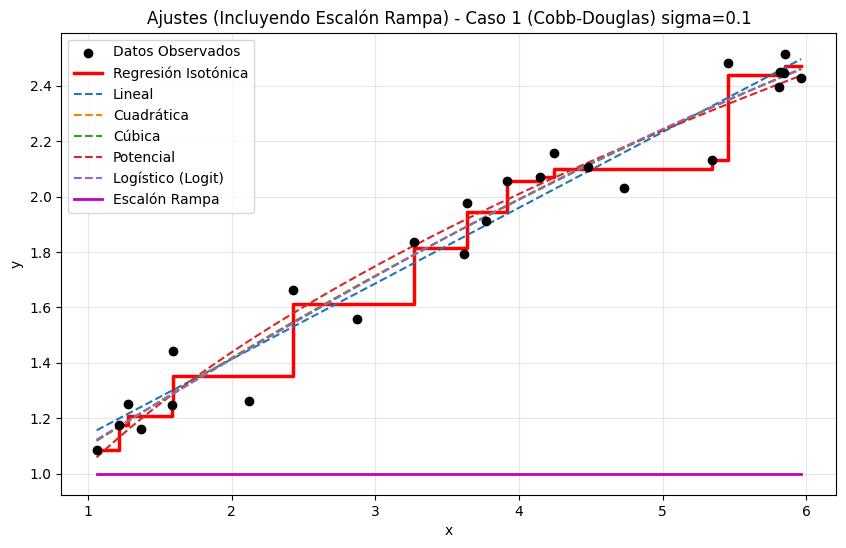

/tmp/ipykernel_749/4254889055.py:22: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_log, _ = curve_fit(modelo_logistico, x, y, p0=[1, 10, 0.5, 0], maxfev=10000)


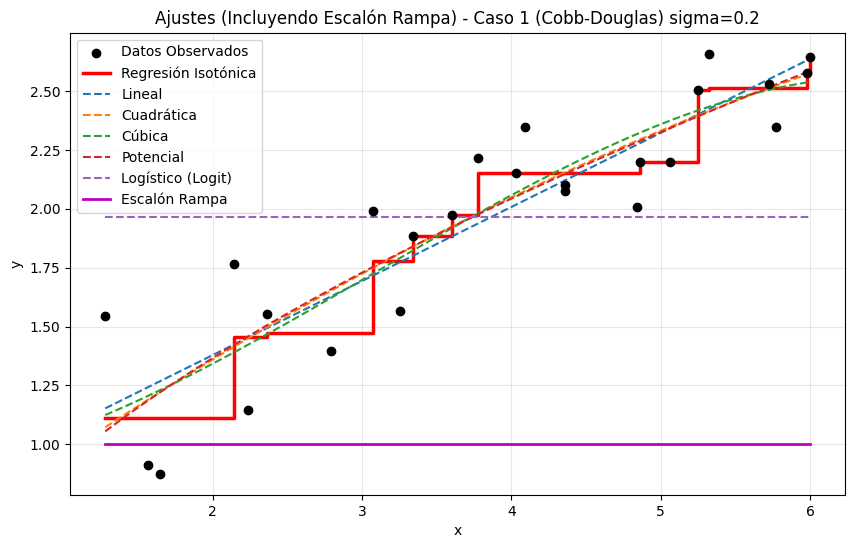

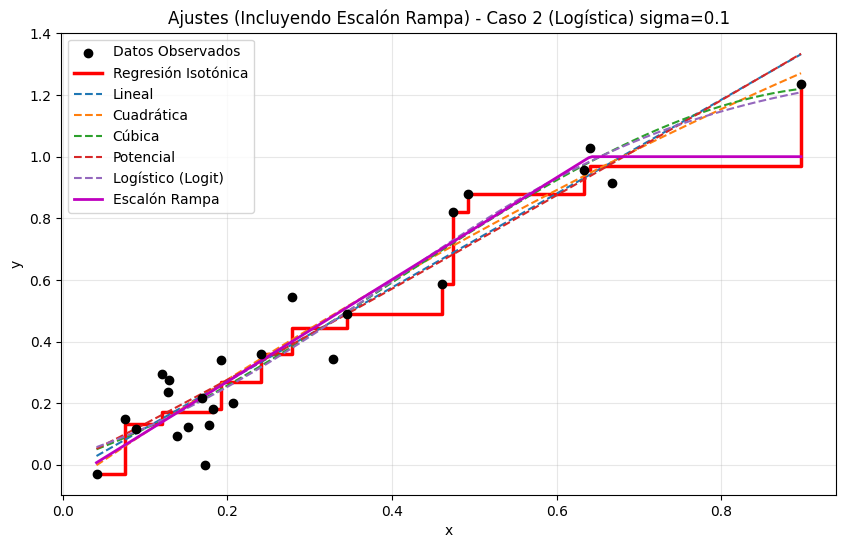

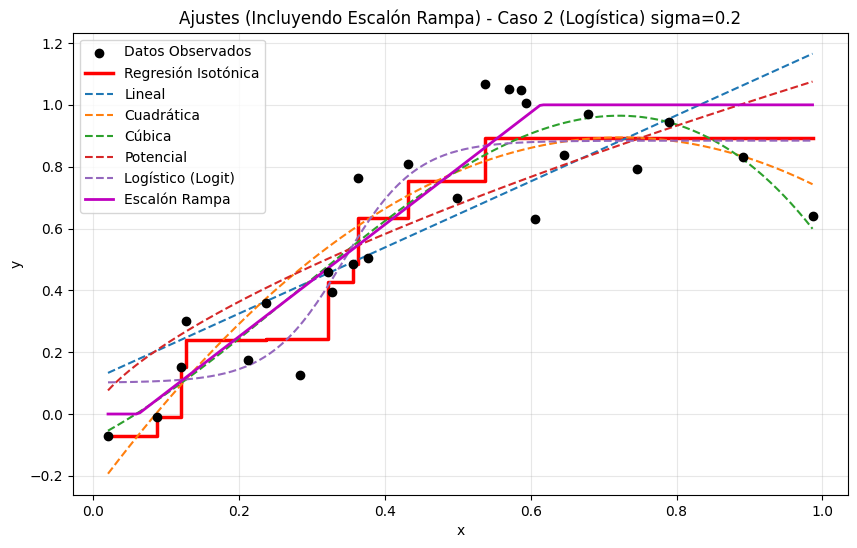

Tabla de Ranking Definitiva (Casos en horizontal, Métodos en vertical):


,Caso 1 (Cobb-Douglas) sigma=0.1,Caso 1 (Cobb-Douglas) sigma=0.2,Caso 2 (Logística) sigma=0.1,Caso 2 (Logística) sigma=0.2,Ranking Medio
Isotónica (QP),1.0,1.0,1.0,1.0,1.00
Cúbica,3.0,2.0,3.0,2.0,2.50
Logístico (Logit),2.0,6.0,2.0,3.0,3.25
Cuadrática,4.0,3.0,4.0,4.0,3.75
Lineal,5.0,5.0,5.0,7.0,5.50
Potencial,6.0,4.0,6.0,6.0,5.50
Escalón Rampa,7.0,7.0,7.0,5.0,6.50


In [10]:
resultados_completos = {}

for nombre, generador, sigma in casos:
    x_c, y_c = generador(n=25, sigma=sigma)
    mses = ajustar_y_evaluar_completo(x_c, y_c, nombre)
    resultados_completos[nombre] = mses

# Convertir a DataFrame
df_resultados_completos = pd.DataFrame(resultados_completos).T

# Obtener rankings horizontales (por cada caso individual)
rankings_completos = df_resultados_completos.rank(axis=1, ascending=True)

# Transponer para tener regresiones verticales y casos horizontales
df_ranking_final_completo = rankings_completos.T

# Añadir la columna de Ranking Medio al final
df_ranking_final_completo['Ranking Medio'] = df_ranking_final_completo.mean(axis=1)

# Ordenar la tabla de menor a mayor ranking medio
df_ranking_final_completo = df_ranking_final_completo.sort_values(by='Ranking Medio')

print("Tabla de Ranking Definitiva (Casos en horizontal, Métodos en vertical):")
display(df_ranking_final_completo)

### Implementación de los Nuevos Modelos

Definiremos:
1. **Isotónica con Rampas:** Tomamos los valores óptimos $\alpha$ de la optimización cuadrática ordenados por $x$ y realizamos una interpolación lineal para evaluar cualquier punto de forma continua y monótona.
2. **Escalón con Activación Única (Rampa Infinita):** Optimizamos el umbral $c$ mediante una búsqueda en rejilla (*grid search*) para encontrar el punto de salto que minimiza el MSE.

In [11]:
def evaluar_isotonica_rampas(x_train, y_iso_train, x_eval):
    """
    Genera una función continua uniendo con segmentos lineales (rampas)
    los puntos obtenidos de la regresión isotónica tradicional.
    """
    sort_idx = np.argsort(x_train)
    x_sorted = x_train[sort_idx]
    y_sorted = y_iso_train[sort_idx]

    # Interpolación lineal unidimensional
    return np.interp(x_eval, x_sorted, y_sorted)

def ajustar_escalon_puro(x, y):
    """
    Ajusta una función escalón puro f(x) = 1 si x >= c else 0
    probando todos los umbrales de activación 'c' posibles en el rango de x.
    """
    c_candidatos = np.linspace(min(x), max(x), 200)
    mejor_c = c_candidatos[0]
    mejor_mse = float('inf')

    for c in c_candidatos:
        y_pred = np.where(x >= c, 1.0, 0.0)
        mse = np.mean((y - y_pred)**2)
        if mse < mejor_mse:
            mejor_mse = mse
            mejor_c = c

    return mejor_c

def modelo_escalon_puro(x, c):
    return np.where(x >= c, 1.0, 0.0)

In [12]:
def resolver_isotonica_rampas_dinamicas(x_train, y_train, x_eval):
    """
    Resuelve la Regresión Monótona Lineal por Tramos de forma continua y óptima.
    Optimiza los valores de los nodos (alpha) asegurando pendientes no negativas m_i >= 0
    en cada intervalo individual [x_i, x_{i+1}].
    """
    # Ordenar puntos de entrenamiento
    sort_idx = np.argsort(x_train)
    x_sorted = x_train[sort_idx]
    y_sorted = y_train[sort_idx]
    n = len(x_sorted)

    # Variables de decisión: el valor de la función en cada nodo de entrenamiento x_i
    alpha = cp.Variable(n)

    # Restricciones: la pendiente en cada intervalo continuo debe ser no negativa
    # m_i = (alpha_{i+1} - alpha_i) / (x_{sorted, i+1} - x_sorted, i) >= 0
    # Como el denominador es estrictamente positivo (x está ordenado y sin duplicados exactos),
    # esto equivale a alpha[i+1] >= alpha[i].
    constraints = []
    for i in range(n - 1):
        constraints.append(alpha[i+1] >= alpha[i])

    # El objetivo es minimizar la distancia cuadrática directa de la línea continua a los puntos de datos.
    # Dado que los nodos coinciden con los puntos x_train, el valor de la función continua
    # en los puntos de entrenamiento es exactamente alpha.
    objective = cp.Minimize(cp.sum_squares(alpha - y_sorted))
    prob = cp.Problem(objective, constraints)
    prob.solve()

    # Retornamos la interpolación continua generada por los nodos óptimos reales
    return np.interp(x_eval, x_sorted, alpha.value)

In [13]:
def ajustar_rampa_basica_residuo(x, residuo):
    """
    Busca la mejor rampa simple (base stump/hinge) que minimice el residuo actual
    mediante una búsqueda en rejilla. Ahora permite escalas positivas o negativas
    (rampas decrecientes o crecientes sin restricciones de signo).
    """
    n = len(x)
    mejor_mse = float('inf')
    mejor_pred = np.zeros_like(x)

    # Puntos candidatos para el inicio (s) y fin (e) de la rampa
    puntos = np.percentile(x, np.linspace(0, 100, 15))

    # Probar diferentes combinaciones de inicio, fin y pendientes
    for i, s in enumerate(puntos):
        for e in puntos[i+1:]:
            # Rampa unitaria entre s y e
            rampa_u = np.clip((x - s) / (e - s), 0, 1)

            # Encontrar el factor de escala óptimo mediante mínimos cuadrados sobre el residuo
            cov = np.cov(rampa_u, residuo)
            var = np.var(rampa_u)
            if var > 1e-9:
                escala = cov[0, 1] / var  # Se elimina la restricción 'max(0.0, escala)'
            else:
                escala = 0.0

            pred = escala * rampa_u
            mse = np.mean((residuo - pred)**2)

            if mse < mejor_mse:
                mejor_mse = mse
                mejor_pred = pred

    return mejor_pred

In [14]:
def regresion_apilada_rampas_secuenciales(x, y, n_etapas=10):
    """
    Modelo de Regresión Monótona Apilada (Pursuit).
    Encuentra y apila secuencialmente tramos de rampa monótonos para modelar los datos.
    """
    # Inicializamos con la predicción media constante
    y_pred = np.ones_like(y) * np.mean(y)

    for etapa in range(n_etapas):
        # Calculamos el residuo actual
        residuo = y - y_pred

        # Buscamos la rampa monótona óptima para este residuo
        mejor_rampa = ajustar_rampa_basica_residuo(x, residuo)

        # Apilamos la rampa monótona
        y_pred += mejor_rampa

    return y_pred

In [15]:
def ajustar_y_evaluar_con_rampas_apiladas(x, y, nombre_caso):
    # 1. Regresión Isotónica Estándar (QP)
    y_iso = resolver_regresion_isotonica(x, y)

    # 2. Regresión de Rampas Apiladas Secuenciales (Nuestra propuesta basada en Pursuit)
    y_apilada = regresion_apilada_rampas_secuenciales(x, y, n_etapas=8)

    # Ajustes paramétricos tradicionales
    popt_lin, _ = curve_fit(modelo_lineal, x, y)
    popt_quad, _ = curve_fit(modelo_cuadratico, x, y)
    popt_cub, _ = curve_fit(modelo_cubico, x, y)

    try:
        popt_log, _ = curve_fit(modelo_logistico, x, y, p0=[1, 10, 0.5, 0], maxfev=10000)
        y_log = modelo_logistico(x, *popt_log)
    except:
        y_log = np.nan * np.ones_like(y)

    y_lin = modelo_lineal(x, *popt_lin)
    y_quad = modelo_cuadratico(x, *popt_quad)
    y_cub = modelo_cubico(x, *popt_cub)

    # Calcular MSEs reales
    mses = {
        'Isotónica (QP)': calcular_mse(y, y_iso),
        'Isotónica c/ Rampas Apiladas (Pursuit)': calcular_mse(y, y_apilada),
        'Lineal': calcular_mse(y, y_lin),
        'Cuadrática': calcular_mse(y, y_quad),
        'Cúbica': calcular_mse(y, y_cub),
        'Logístico (Logit)': calcular_mse(y, y_log) if not np.isnan(y_log[0]) else np.nan
    }

    # Representación Gráfica comparativa detallada
    x_grid = np.linspace(min(x), max(x), 300)
    sort_idx = np.argsort(x)

    plt.figure(figsize=(11, 7))
    plt.scatter(x, y, color='black', zorder=5, label='Datos Observados')

    # Graficar la comparación de enfoques
    plt.step(x[sort_idx], y_iso[sort_idx], where='post', color='red', alpha=0.5, linewidth=2, label='Isotónica Estándar (Escalones QP)')

    # Para graficar la predicción continua del modelo de rampas apiladas
    # Creamos una aproximación del modelo sobre la rejilla densa x_grid
    y_apilada_grid = np.ones_like(x_grid) * np.mean(y)
    residuo_grid = y - np.mean(y)

    # Re-simulamos el apilamiento acumulativo para la visualización suave
    y_temp = np.ones_like(y) * np.mean(y)
    for _ in range(8):
        res = y - y_temp
        # Encontrar rampa óptima
        n = len(x)
        puntos = np.percentile(x, np.linspace(0, 100, 15))
        mejor_mse = float('inf')
        mejor_s, mejor_e, mejor_escala = 0, 0, 0

        for i, s in enumerate(puntos):
            for e in puntos[i+1:]:
                rampa_u = np.clip((x - s) / (e - s), 0, 1)
                cov = np.cov(rampa_u, res)
                var = np.var(rampa_u)
                escala = cov[0, 1] / var if var > 1e-9 else 0.0
                escala = max(0.0, escala)
                mse = np.mean((res - escala * rampa_u)**2)
                if mse < mejor_mse:
                    mejor_mse = mse
                    mejor_s, mejor_e, mejor_escala = s, e, escala

        y_temp += mejor_escala * np.clip((x - mejor_s) / (mejor_e - mejor_s), 0, 1)
        y_apilada_grid += mejor_escala * np.clip((x_grid - mejor_s) / (mejor_e - mejor_s), 0, 1)

    plt.plot(x_grid, y_apilada_grid, 'b-', linewidth=2.5, label='Rampas Apiladas (Monotone Pursuit)')
    if not np.isnan(y_log[0]):
        plt.plot(x_grid, modelo_logistico(x_grid, *popt_log), 'g--', label='Logístico (Logit)')

    plt.title(f'Búsqueda y Apilamiento de Rampas Monótonas - {nombre_caso}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return mses

/tmp/ipykernel_749/4124598016.py:2: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k * (x - x0))) + c
/tmp/ipykernel_749/141763356.py:14: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_log, _ = curve_fit(modelo_logistico, x, y, p0=[1, 10, 0.5, 0], maxfev=10000)


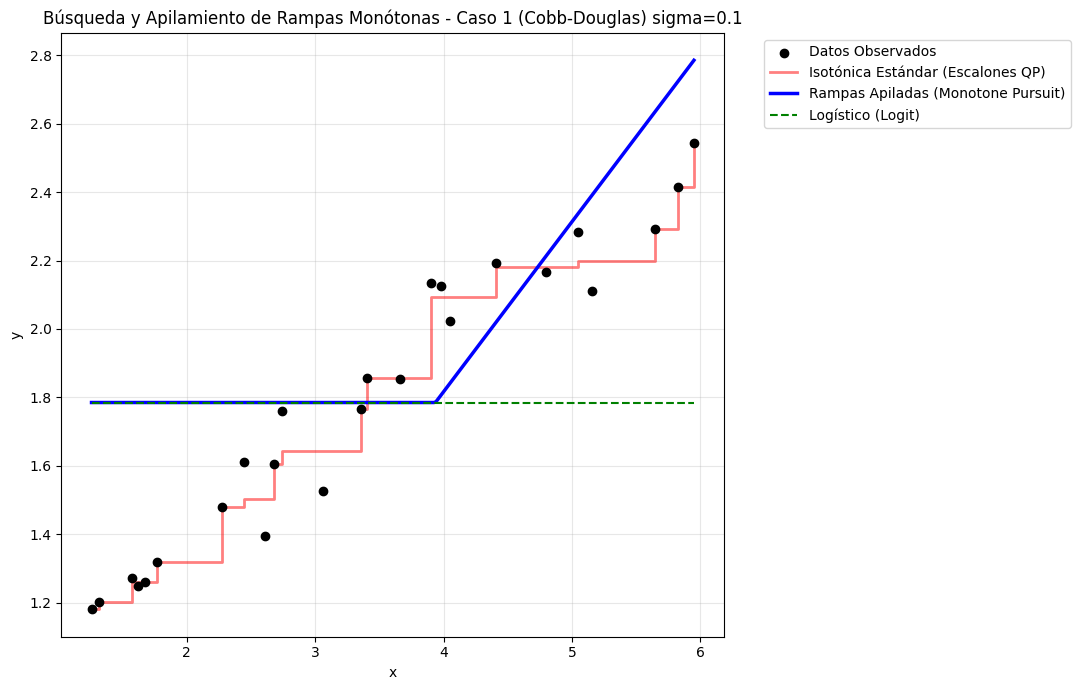

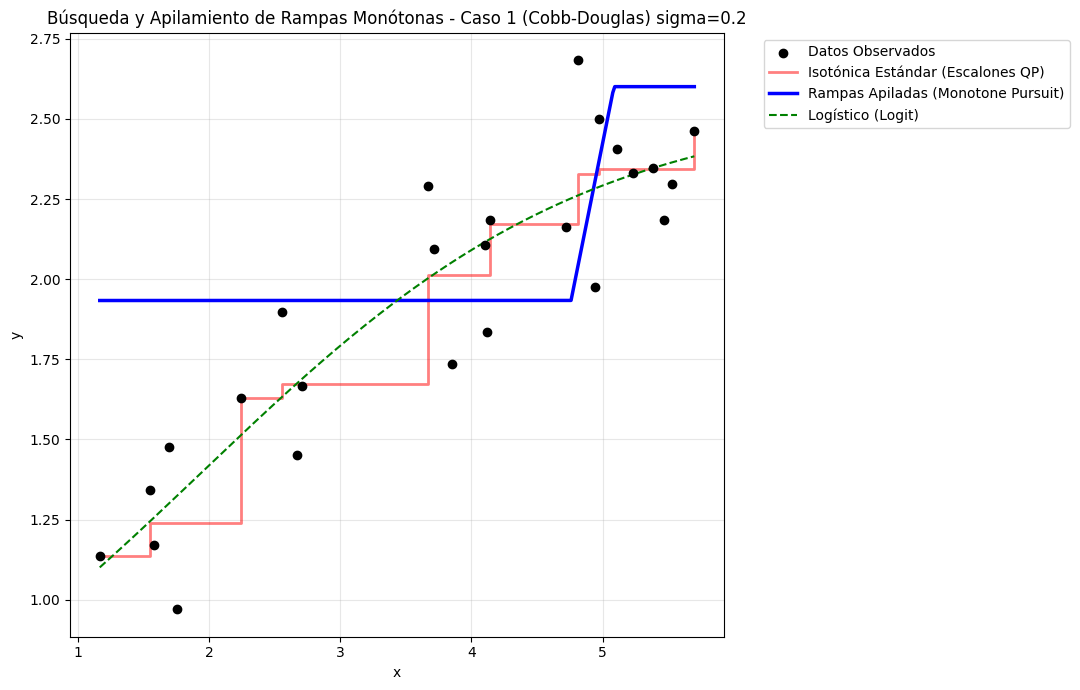

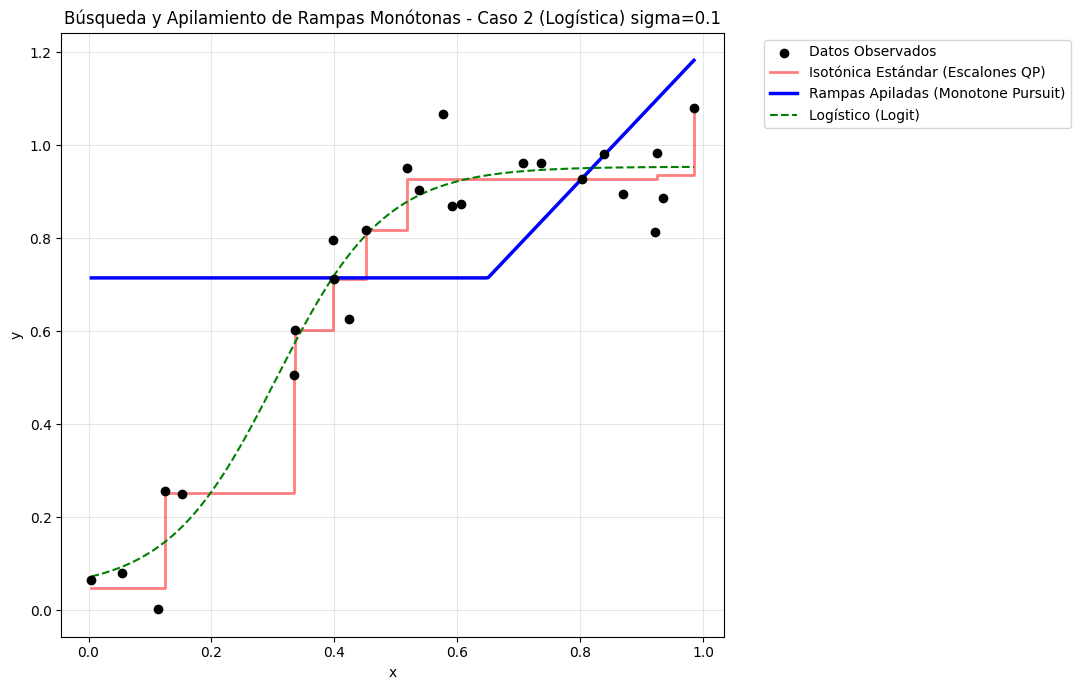

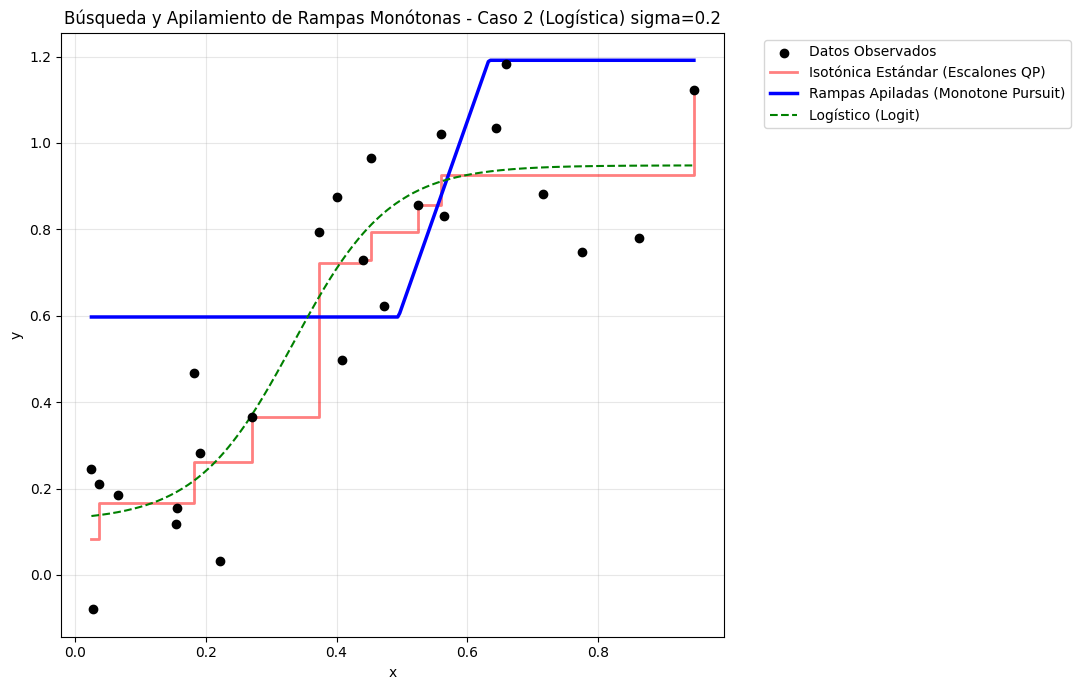

,Caso 1 (Cobb-Douglas) sigma=0.1,Caso 1 (Cobb-Douglas) sigma=0.2,Caso 2 (Logística) sigma=0.1,Caso 2 (Logística) sigma=0.2,Ranking Medio,MSE Medio
Isotónica (QP),1.0,1.0,1.0,1.0,1.00,0.013362
Cúbica,2.0,2.0,3.0,3.0,2.50,0.020413
Logístico (Logit),6.0,3.0,2.0,2.0,3.25,0.059892
Cuadrática,3.0,4.0,4.0,4.0,3.75,0.020979
Lineal,4.0,5.0,5.0,5.0,4.75,0.028721
Isotónica c/ Rampas Apiladas (Pursuit),5.0,6.0,6.0,6.0,5.75,0.113254


In [16]:
resultados_apilados = {}

# Ejecutar en todos los casos utilizando los mismos escenarios experimentales estables
for nombre, generador, sigma in casos:
    x_c, y_c = generador(n=25, sigma=sigma)
    mses = ajustar_y_evaluar_con_rampas_apiladas(x_c, y_c, nombre)
    resultados_apilados[nombre] = mses

# Construcción de la tabla de resultados del modelo Pursuit
df_resultados_apilados = pd.DataFrame(resultados_apilados).T
df_ranking_apilado = df_resultados_apilados.rank(axis=1, ascending=True).T

# Añadir promedios globales de rendimiento
df_ranking_apilado['Ranking Medio'] = df_ranking_apilado.mean(axis=1)
df_ranking_apilado = df_ranking_apilado.sort_values(by='Ranking Medio')

df_mse_apilado_promedio = df_resultados_apilados.mean(axis=0).to_frame(name='MSE Medio')
tabla_consolidada_apilada = df_ranking_apilado.join(df_mse_apilado_promedio)

display(tabla_consolidada_apilada)

In [17]:
def ajustar_y_evaluar_con_rampas_dinamicas(x, y, nombre_caso):
    # 1. Regresión Isotónica Estándar (QP)
    y_iso = resolver_regresion_isotonica(x, y)

    # 2. Regresión Isotónica con Rampas Dinámicas (Optimización Activa de Pendientes)
    y_rampas_din = resolver_isotonica_rampas_dinamicas(x, y, x)

    # Ajustes paramétricos tradicionales
    popt_lin, _ = curve_fit(modelo_lineal, x, y)
    popt_quad, _ = curve_fit(modelo_cuadratico, x, y)
    popt_cub, _ = curve_fit(modelo_cubico, x, y)

    try:
        popt_pot, _ = curve_fit(modelo_potencial, x, y, p0=[1, 1], maxfev=5000)
        y_pot = modelo_potencial(x, *popt_pot)
    except:
        y_pot = np.nan * np.ones_like(y)

    try:
        popt_log, _ = curve_fit(modelo_logistico, x, y, p0=[1, 10, 0.5, 0], maxfev=10000)
        y_log = modelo_logistico(x, *popt_log)
    except:
        y_log = np.nan * np.ones_like(y)

    # Escalón Rampa Truncado
    try:
        popt_rampa, _ = curve_fit(modelo_escalon_rampa, x, y, p0=[2.0, 0.2], maxfev=10000)
        y_rampa = modelo_escalon_rampa(x, *popt_rampa)
    except:
        y_rampa = np.nan * np.ones_like(y)

    # Escalón Puro (Activación)
    c_optimo = ajustar_escalon_puro(x, y)
    y_escalon_puro = modelo_escalon_puro(x, c_optimo)

    y_lin = modelo_lineal(x, *popt_lin)
    y_quad = modelo_cuadratico(x, *popt_quad)
    y_cub = modelo_cubico(x, *popt_cub)

    # Calcular MSEs reales evaluados contra las observaciones de entrenamiento (y)
    mses = {
        'Isotónica (QP)': calcular_mse(y, y_iso),
        'Isotónica c/ Rampas Dinámicas': calcular_mse(y, y_rampas_din),
        'Lineal': calcular_mse(y, y_lin),
        'Cuadrática': calcular_mse(y, y_quad),
        'Cúbica': calcular_mse(y, y_cub),
        'Potencial': calcular_mse(y, y_pot) if not np.isnan(y_pot[0]) else np.nan,
        'Logístico (Logit)': calcular_mse(y, y_log) if not np.isnan(y_log[0]) else np.nan,
        'Escalón Rampa': calcular_mse(y, y_rampa) if not np.isnan(y_rampa[0]) else np.nan,
        'Escalón Puro': calcular_mse(y, y_escalon_puro)
    }

    # Representación Gráfica con rejilla densa
    x_grid = np.linspace(min(x), max(x), 300)
    sort_idx = np.argsort(x)

    plt.figure(figsize=(11, 7))
    plt.scatter(x, y, color='black', zorder=5, label='Datos Observados')

    # Graficar la comparación de ambas aproximaciones
    plt.step(x[sort_idx], y_iso[sort_idx], where='post', color='red', alpha=0.6, linewidth=2, label='Isotónica Estándar (Escalones QP)')
    plt.plot(x_grid, resolver_isotonica_rampas_dinamicas(x, y, x_grid), 'g-', linewidth=2.5, label='Rampas Dinámicas Monótonas (Optimizado)')

    # Otros Modelos clave
    plt.plot(x_grid, modelo_cubico(x_grid, *popt_cub), 'y--', label='Cúbica')
    if not np.isnan(y_log[0]):
        plt.plot(x_grid, modelo_logistico(x_grid, *popt_log), 'c--', label='Logístico (Logit)')

    plt.title(f'Comparación con Rampas Dinámicas Activas - {nombre_caso}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return mses

### Implementación de Modelos de Rampa Paramétrica con y sin Pesos ($w$)

Definiremos e integraremos dos formulaciones de la rampa paramétrica para estudiar la ganancia del parámetro de peso $w$:
1. **Rampa con Peso y Pendiente Interna ($w$ y $m$):** $f(x) = w \cdot \max(0, \min(m(x-c), 1))$
2. **Rampa Monótona Simple ($m$):** $f(x) = m \cdot \max(0, \min(x-c, 1))$

In [18]:
def modelo_rampa_con_w(x, w, m, c):
    # w * step_incl(m * (x - c))
    return w * np.clip(m * (x - c), 0, 1)

def modelo_rampa_sin_w(x, m, c):
    # m * step_incl(x - c)
    return m * np.clip(x - c, 0, 1)

def ajustar_modelos_rampa_paramétrica(x, y):
    # Se eliminan los límites de monotonicidad forzada (bounds=[0.0, ...])
    # para permitir que w, m y c exploren todo el espacio real (negativos y positivos).
    try:
        # p0: w=1.0, m=2.0, c=min(x)
        popt_con_w, _ = curve_fit(modelo_rampa_con_w, x, y, p0=[1.0, 2.0, float(np.min(x))],
                                  maxfev=15000)
    except:
        popt_con_w = None

    try:
        # p0: m=2.0, c=min(x)
        popt_sin_w, _ = curve_fit(modelo_rampa_sin_w, x, y, p0=[2.0, float(np.min(x))],
                                  maxfev=15000)
    except:
        popt_sin_w = None

    return popt_con_w, popt_sin_w

In [19]:
def evaluar_y_comparar_rampas_pesos(x, y, nombre_caso):
    # Obtener ajustes de los nuevos modelos de rampa
    popt_con_w, popt_sin_w = ajustar_modelos_rampa_paramétrica(x, y)

    # Ajustar también la regresión isotónica tradicional para referencia
    y_iso = resolver_regresion_isotonica(x, y)

    y_pred_con_w = modelo_rampa_con_w(x, *popt_con_w) if popt_con_w is not None else np.nan * np.ones_like(y)
    y_pred_sin_w = modelo_rampa_sin_w(x, *popt_sin_w) if popt_sin_w is not None else np.nan * np.ones_like(y)

    # Calcular MSEs
    mse_con_w = calcular_mse(y, y_pred_con_w)
    mse_sin_w = calcular_mse(y, y_pred_sin_w)
    mse_iso = calcular_mse(y, y_iso)

    # Visualización detallada de ambas rampas
    x_grid = np.linspace(min(x), max(x), 300)

    plt.figure(figsize=(10, 6))
    plt.scatter(x, y, color='black', label='Datos Observados', zorder=5)

    sort_idx = np.argsort(x)
    plt.step(x[sort_idx], y_iso[sort_idx], where='post', color='red', alpha=0.4, linestyle='--', label='Isotónica (QP)')

    if popt_con_w is not None:
        plt.plot(x_grid, modelo_rampa_con_w(x_grid, *popt_con_w), 'blue', linewidth=2, label=f'Rampa con w (MSE={mse_con_w:.4f})')
    if popt_sin_w is not None:
        plt.plot(x_grid, modelo_rampa_sin_w(x_grid, *popt_sin_w), 'green', linewidth=2, label=f'Rampa sin w (MSE={mse_sin_w:.4f})')

    plt.title(f'Comparación de Formulaciones de Rampa - {nombre_caso}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    return {
        'Rampa con Peso (w)': mse_con_w,
        'Rampa sin Peso': mse_sin_w,
        'Isotónica (QP)': mse_iso
    }

/tmp/ipykernel_749/570780748.py:14: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_con_w, _ = curve_fit(modelo_rampa_con_w, x, y, p0=[1.0, 2.0, float(np.min(x))],


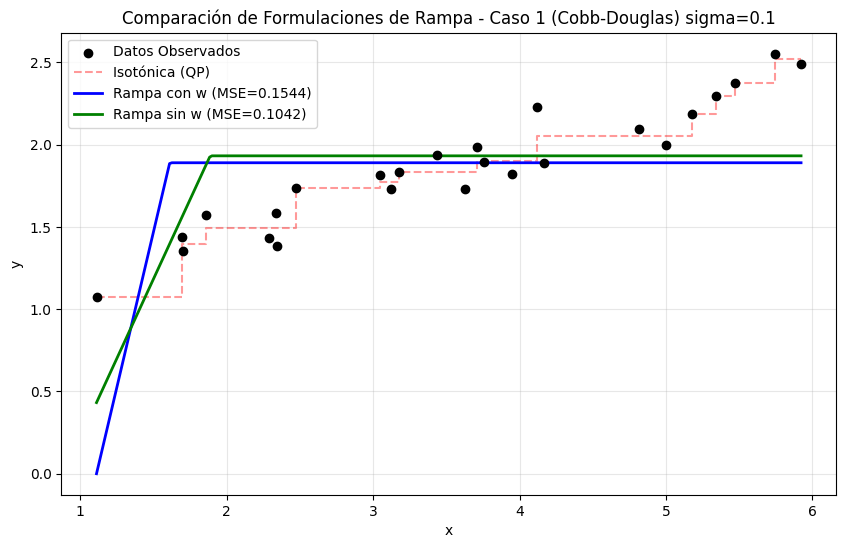

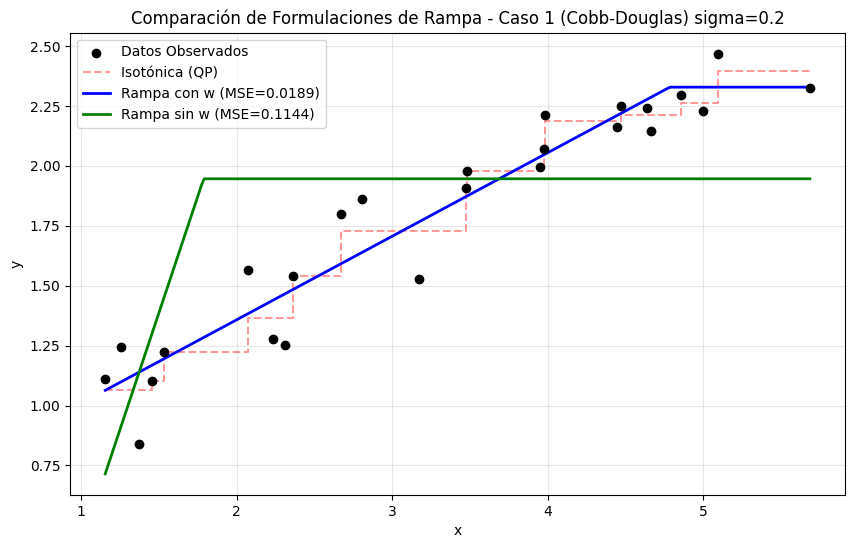

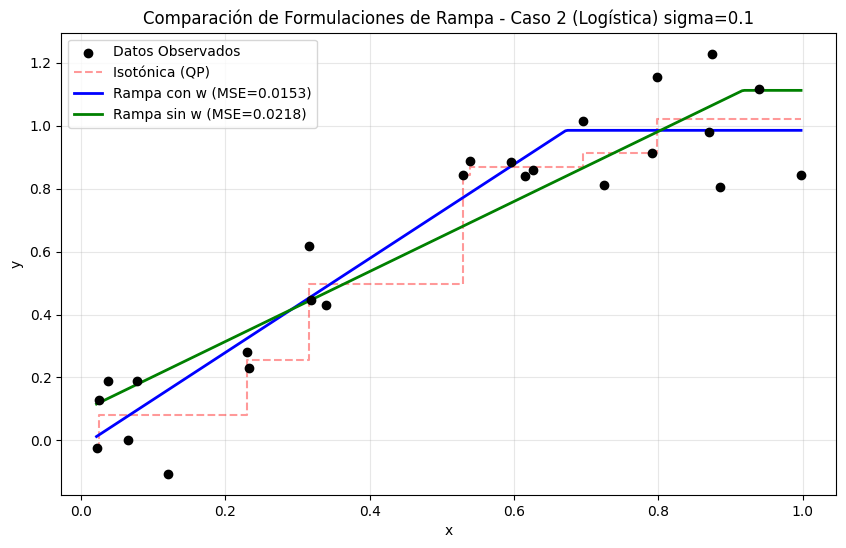

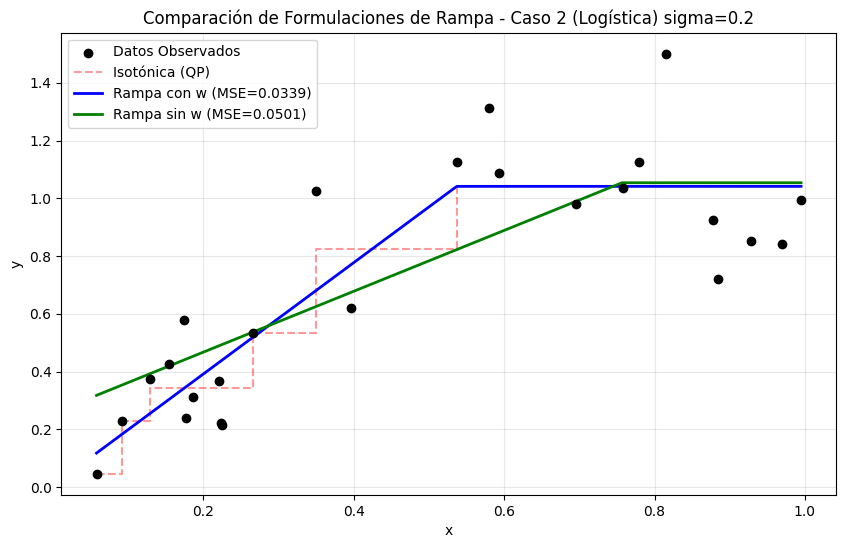

Tabla Comparativa de MSE:


,Rampa con Peso (w),Rampa sin Peso,Isotónica (QP)
Caso 1 (Cobb-Douglas) sigma=0.1,0.154432,0.104175,0.005399
Caso 1 (Cobb-Douglas) sigma=0.2,0.018942,0.114377,0.009166
Caso 2 (Logística) sigma=0.1,0.015312,0.021779,0.010499
Caso 2 (Logística) sigma=0.2,0.033943,0.050083,0.027514



Tabla de Rankings de Modelos de Rampa (Menor Ranking es mejor):


,Caso 1 (Cobb-Douglas) sigma=0.1,Caso 1 (Cobb-Douglas) sigma=0.2,Caso 2 (Logística) sigma=0.1,Caso 2 (Logística) sigma=0.2,Ranking Medio
Isotónica (QP),1.0,1.0,1.0,1.0,1.00
Rampa con Peso (w),3.0,2.0,2.0,2.0,2.25
Rampa sin Peso,2.0,3.0,3.0,3.0,2.75


In [20]:
resultados_rampas = {}
for nombre, generador, sigma in casos:
    x_c, y_c = generador(n=25, sigma=sigma)
    res = evaluar_y_comparar_rampas_pesos(x_c, y_c, nombre)
    resultados_rampas[nombre] = res

# Generar tabla de comparación y rankings
df_res_rampas = pd.DataFrame(resultados_rampas).T
df_ranking_rampas = df_res_rampas.rank(axis=1, ascending=True).T
df_ranking_rampas['Ranking Medio'] = df_ranking_rampas.mean(axis=1)

print("Tabla Comparativa de MSE:")
display(df_res_rampas)

print("\nTabla de Rankings de Modelos de Rampa (Menor Ranking es mejor):")
display(df_ranking_rampas.sort_values(by='Ranking Medio'))

### Evaluación y Comparativa Final Consolidada de Todos los Modelos

En este bloque unificaremos todos los modelos desarrollados en la práctica para realizar una comparativa integral:
* **Isotónica Estándar (QP)**
* **Isotónica con Rampas Dinámicas (Tramos continuos)**
* **Rampas Apiladas (Monotone Pursuit - Greedy)**
* **Rampa Paramétrica Completa (con Peso $w$)**
* **Rampa Paramétrica Simple (sin Peso $w$)**
* **Modelos Polinómicos (Lineal, Cuadrático, Cúbico)**
* **Modelo Potencial**
* **Modelo Logístico (Logit)**
* **Escalón Rampa Truncado**
* **Escalón Puro (Activación)**

In [21]:
def evaluar_todos_los_modelos_unificados(x, y, nombre_caso):
    # 1. Isotónica Estándar
    y_iso = resolver_regresion_isotonica(x, y)

    # 2. Isotónica con Rampas Dinámicas (Tramos continuos óptimos)
    y_rampas_din = resolver_isotonica_rampas_dinamicas(x, y, x)

    # 3. Rampas Apiladas (Monotone Pursuit - 8 etapas con rampas con signo libre)
    y_apilada = regresion_apilada_rampas_secuenciales(x, y, n_etapas=8)

    # Ajustes con curve_fit
    popt_lin, _ = curve_fit(modelo_lineal, x, y)
    popt_quad, _ = curve_fit(modelo_cuadratico, x, y)
    popt_cub, _ = curve_fit(modelo_cubico, x, y)

    try:
        popt_pot, _ = curve_fit(modelo_potencial, x, y, p0=[1, 1], maxfev=5000)
        y_pot = modelo_potencial(x, *popt_pot)
    except:
        y_pot = np.nan * np.ones_like(y)

    try:
        popt_log, _ = curve_fit(modelo_logistico, x, y, p0=[1, 10, 0.5, 0], maxfev=10000)
        y_log = modelo_logistico(x, *popt_log)
    except:
        y_log = np.nan * np.ones_like(y)

    # Nuevos modelos paramétricos de rampa con y sin w (con signo libre)
    popt_con_w, popt_sin_w = ajustar_modelos_rampa_paramétrica(x, y)
    y_rampa_con_w = modelo_rampa_con_w(x, *popt_con_w) if popt_con_w is not None else np.nan * np.ones_like(y)
    y_rampa_sin_w = modelo_rampa_sin_w(x, *popt_sin_w) if popt_sin_w is not None else np.nan * np.ones_like(y)

    # Modelos de un único escalón
    try:
        popt_rampa, _ = curve_fit(modelo_escalon_rampa, x, y, p0=[2.0, 0.2], maxfev=10000)
        y_rampa_trunc = modelo_escalon_rampa(x, *popt_rampa)
    except:
        y_rampa_trunc = np.nan * np.ones_like(y)

    c_optimo = ajustar_escalon_puro(x, y)
    y_escalon_puro = modelo_escalon_puro(x, c_optimo)

    # Generar predicciones para graficar sobre malla continua
    x_grid = np.linspace(min(x), max(x), 300)

    # Diccionario de MSEs
    mses = {
        'Isotónica (QP)': calcular_mse(y, y_iso),
        'Isotónica c/ Rampas Dinámicas': calcular_mse(y, y_rampas_din),
        'Rampas Apiladas (Pursuit)': calcular_mse(y, y_apilada),
        'Rampa Paramétrica c/ Peso (w)': calcular_mse(y, y_rampa_con_w),
        'Rampa Paramétrica s/ Peso': calcular_mse(y, y_rampa_sin_w),
        'Cúbica': calcular_mse(y, modelo_cubico(x, *popt_cub)),
        'Cuadrática': calcular_mse(y, modelo_cuadratico(x, *popt_quad)),
        'Lineal': calcular_mse(y, modelo_lineal(x, *popt_lin)),
        'Potencial': calcular_mse(y, y_pot) if not np.isnan(y_pot[0]) else np.nan,
        'Logístico (Logit)': calcular_mse(y, y_log) if not np.isnan(y_log[0]) else np.nan,
        'Escalón Rampa Truncada': calcular_mse(y, y_rampa_trunc) if not np.isnan(y_rampa_trunc[0]) else np.nan,
        'Escalón Puro': calcular_mse(y, y_escalon_puro)
    }

    # Plot de comparación detallada
    plt.figure(figsize=(12, 7))
    plt.scatter(x, y, color='black', s=40, zorder=5, label='Datos Observados')

    sort_idx = np.argsort(x)
    plt.step(x[sort_idx], y_iso[sort_idx], where='post', color='red', alpha=0.5, linewidth=2, label='Isotónica (QP)')
    plt.plot(x_grid, resolver_isotonica_rampas_dinamicas(x, y, x_grid), 'g-', linewidth=2.5, label='Rampas Dinámicas (Tramos)')

    if popt_con_w is not None:
        plt.plot(x_grid, modelo_rampa_con_w(x_grid, *popt_con_w), 'blue', linewidth=2, label='Rampa c/ Peso (w) [Signo Libre]')
    if popt_sin_w is not None:
        plt.plot(x_grid, modelo_rampa_sin_w(x_grid, *popt_sin_w), 'g--', linewidth=1.5, label='Rampa s/ Peso [Signo Libre]')

    plt.plot(x_grid, modelo_cubico(x_grid, *popt_cub), 'y:', label='Regresión Cúbica')

    # Re-simular aproximación del modelo de rampas apiladas con signo libre
    y_apilada_grid = np.ones_like(x_grid) * np.mean(y)
    y_temp = np.ones_like(y) * np.mean(y)
    for _ in range(8):
        res_it = y - y_temp
        puntos = np.percentile(x, np.linspace(0, 100, 15))
        mejor_mse_it = float('inf')
        mejor_s, mejor_e, mejor_escala = 0, 0, 0
        for i, s in enumerate(puntos):
            for e in puntos[i+1:]:
                rampa_u = np.clip((x - s) / (e - s), 0, 1)
                cov = np.cov(rampa_u, res_it)
                var = np.var(rampa_u)
                escala = cov[0, 1] / var if var > 1e-9 else 0.0
                # Sin restricción max(0.0, escala)
                mse_it = np.mean((res_it - escala * rampa_u)**2)
                if mse_it < mejor_mse_it:
                    mejor_mse_it = mse_it
                    mejor_s, mejor_e, mejor_escala = s, e, escala
        y_temp += mejor_escala * np.clip((x - mejor_s) / (mejor_e - mejor_s), 0, 1)
        y_apilada_grid += mejor_escala * np.clip((x_grid - mejor_s) / (mejor_e - mejor_s), 0, 1)

    plt.plot(x_grid, y_apilada_grid, color='darkorange', linestyle='-.', linewidth=2, label='Rampas Apiladas (Pursuit) [Signo Libre]')

    plt.title(f'Comparación de Todos los Modelos (Signos Libres) - {nombre_caso}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return mses

/tmp/ipykernel_749/4124598016.py:2: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k * (x - x0))) + c
/tmp/ipykernel_749/570780748.py:14: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_con_w, _ = curve_fit(modelo_rampa_con_w, x, y, p0=[1.0, 2.0, float(np.min(x))],
/tmp/ipykernel_749/2592522554.py:35: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_rampa, _ = curve_fit(modelo_escalon_rampa, x, y, p0=[2.0, 0.2], maxfev=10000)


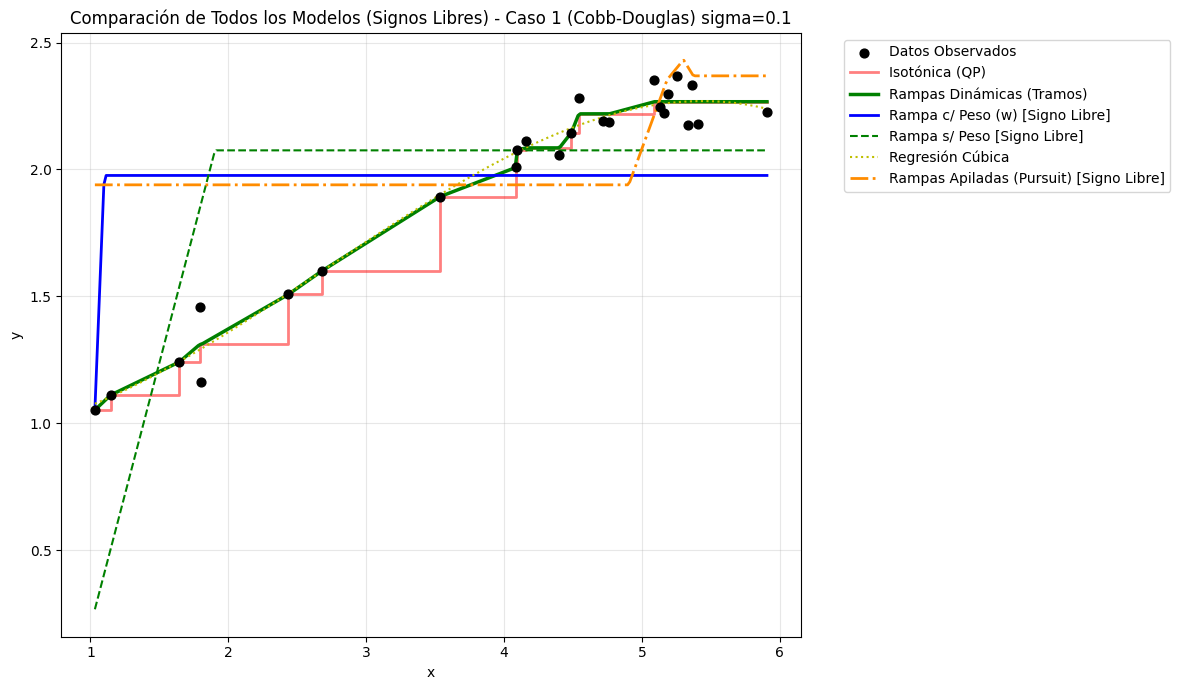

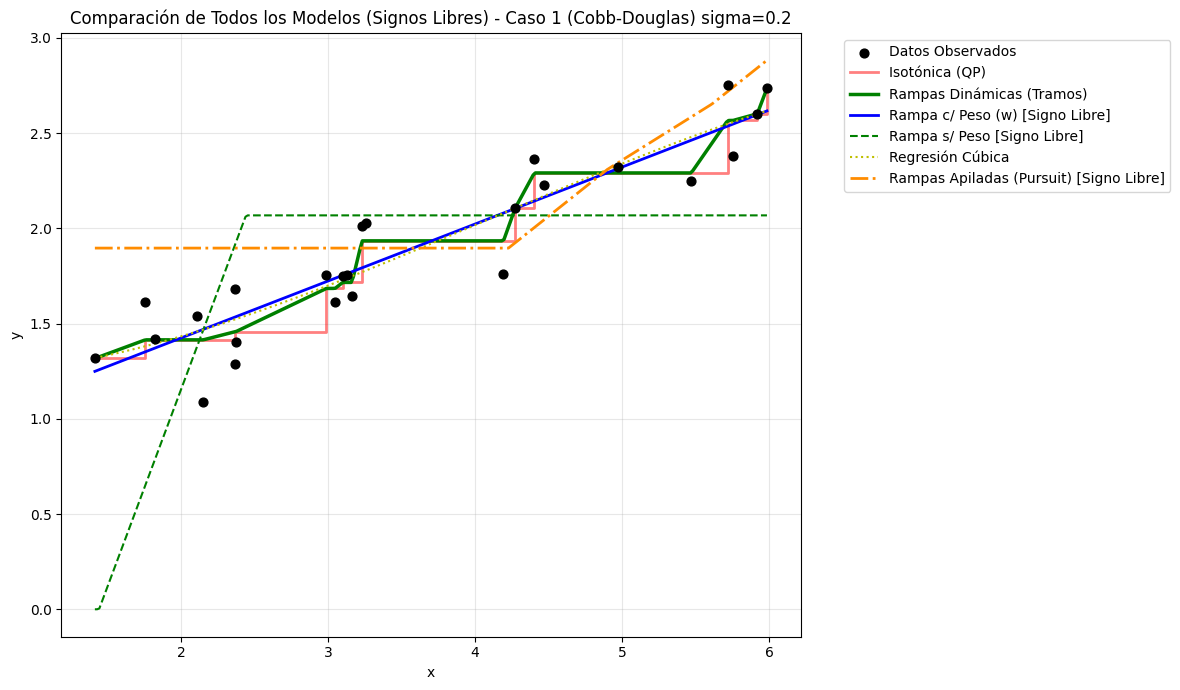

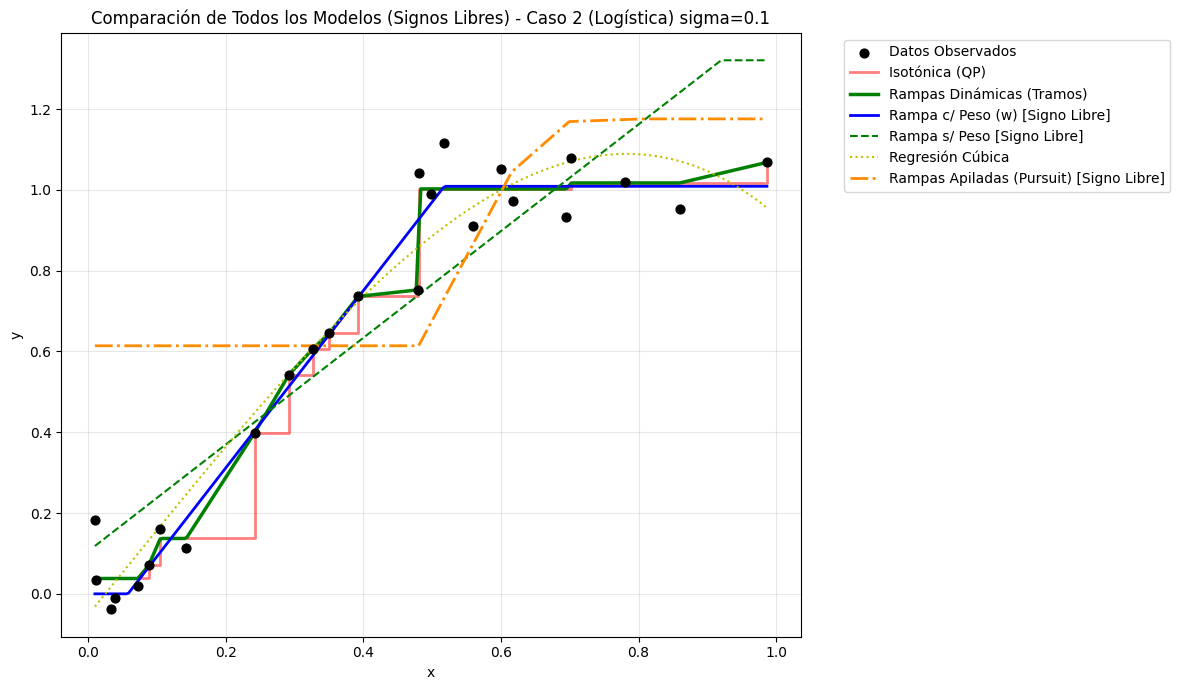

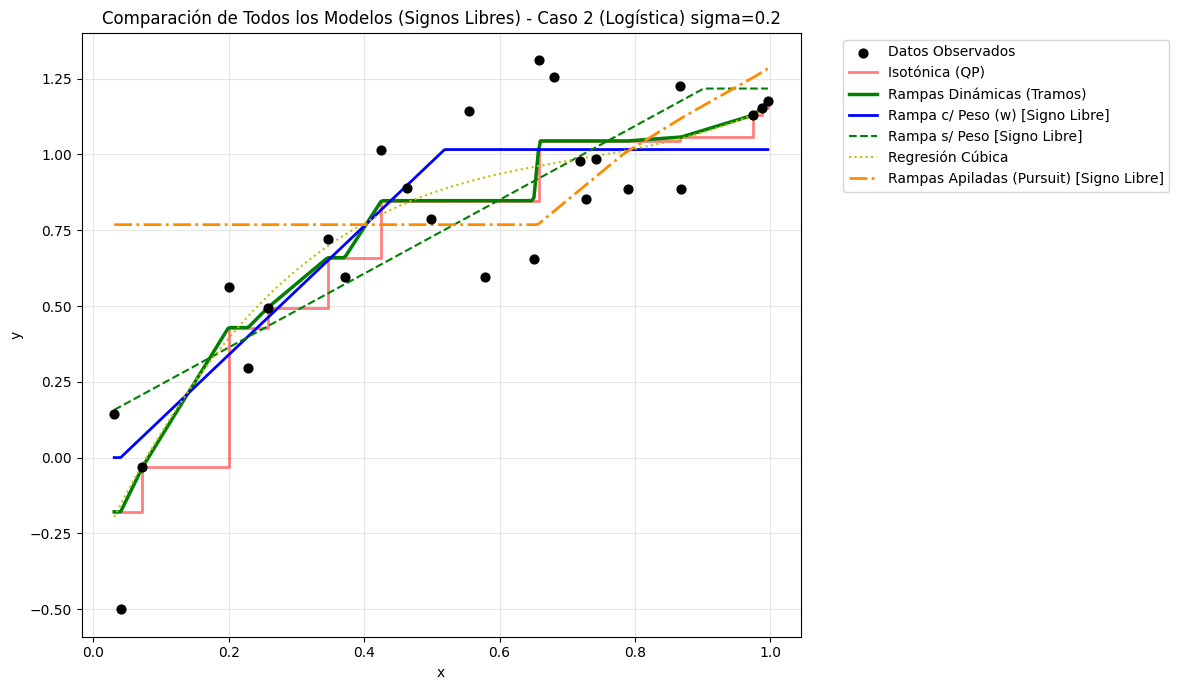


--- TABLA GLOBAL DE RANKINGS Y METRICAS DE RENDIMIENTO ---


,Caso 1 (Cobb-Douglas) sigma=0.1,Caso 1 (Cobb-Douglas) sigma=0.2,Caso 2 (Logística) sigma=0.1,Caso 2 (Logística) sigma=0.2,Ranking Medio,MSE Medio Real
Isotónica (QP),1.5,2.0,1.0,1.0,1.375,0.012644
Isotónica c/ Rampas Dinámicas,1.5,1.0,2.0,2.0,1.625,0.012644
Cúbica,3.0,3.0,6.0,3.0,3.750,0.020103
Logístico (Logit),4.0,4.0,5.0,4.0,4.250,0.019475
Cuadrática,5.0,5.0,7.0,5.0,5.500,0.021591
Rampa Paramétrica c/ Peso (w),10.0,7.0,3.0,6.0,6.500,0.055801
Potencial,6.0,8.0,8.0,8.0,7.500,0.027843
Lineal,7.0,6.0,10.0,10.0,8.250,0.031851
Escalón Rampa Truncada,11.5,11.5,4.0,7.0,8.500,0.529906
Rampa Paramétrica s/ Peso,8.0,10.0,9.0,9.0,9.000,0.110780


In [22]:
resultados_gran_comparativa = {}

# Ejecución de todos los modelos unificados sobre todos los escenarios
for nombre, generador, sigma in casos:
    x_c, y_c = generador(n=25, sigma=sigma)
    mses_modelos = evaluar_todos_los_modelos_unificados(x_c, y_c, nombre)
    resultados_gran_comparativa[nombre] = mses_modelos

# Construcción de DataFrame de resultados comparativos finales
df_mse_global = pd.DataFrame(resultados_gran_comparativa).T

# Obtención de rankings horizontales por escenario
df_ranking_global = df_mse_global.rank(axis=1, ascending=True).T

# Añadir métricas de síntesis promedio
df_ranking_global['Ranking Medio'] = df_ranking_global.mean(axis=1)
df_mse_medio_global = df_mse_global.mean(axis=0).to_frame(name='MSE Medio Real')

tabla_ranking_final_absoluta = df_ranking_global.join(df_mse_medio_global).sort_values(by='Ranking Medio')

print("\n--- TABLA GLOBAL DE RANKINGS Y METRICAS DE RENDIMIENTO ---")
display(tabla_ranking_final_absoluta)

/tmp/ipykernel_749/4124598016.py:2: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k * (x - x0))) + c
/tmp/ipykernel_749/1969719200.py:20: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_log, _ = curve_fit(modelo_logistico, x, y, p0=[1, 10, 0.5, 0], maxfev=10000)
/tmp/ipykernel_749/1969719200.py:27: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_rampa, _ = curve_fit(modelo_escalon_rampa, x, y, p0=[2.0, 0.2], maxfev=10000)


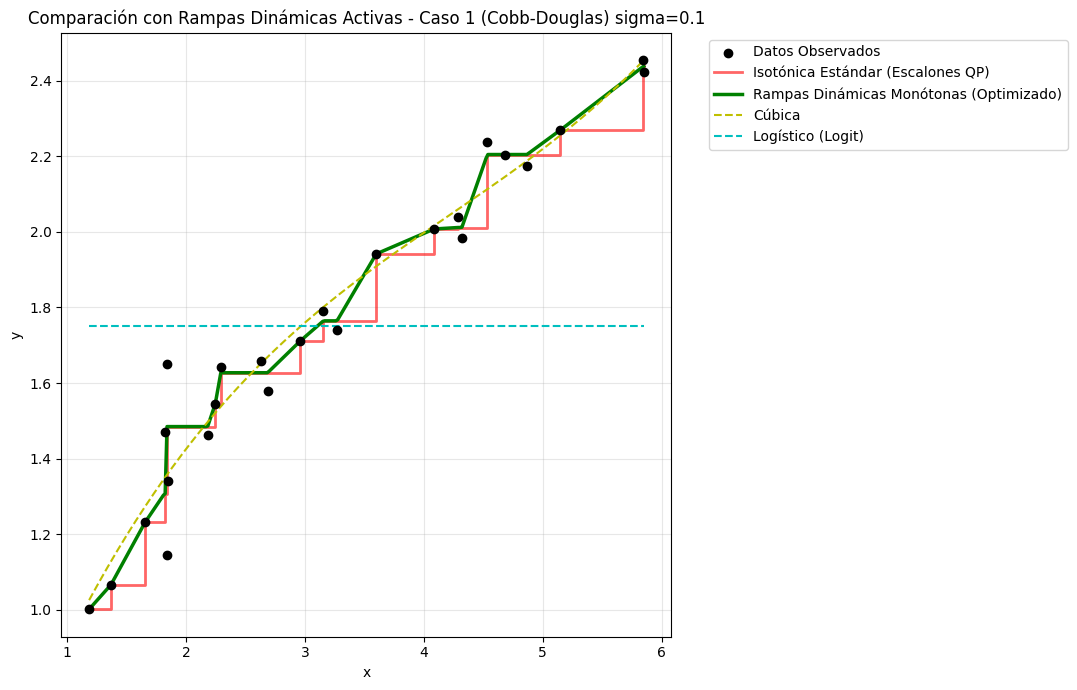

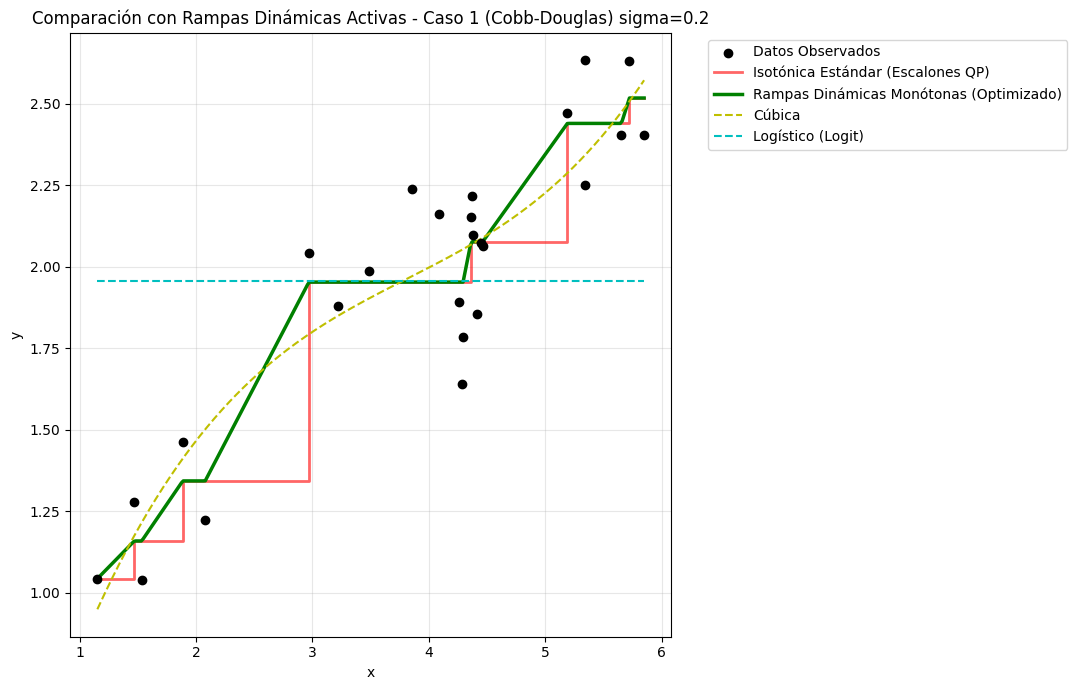

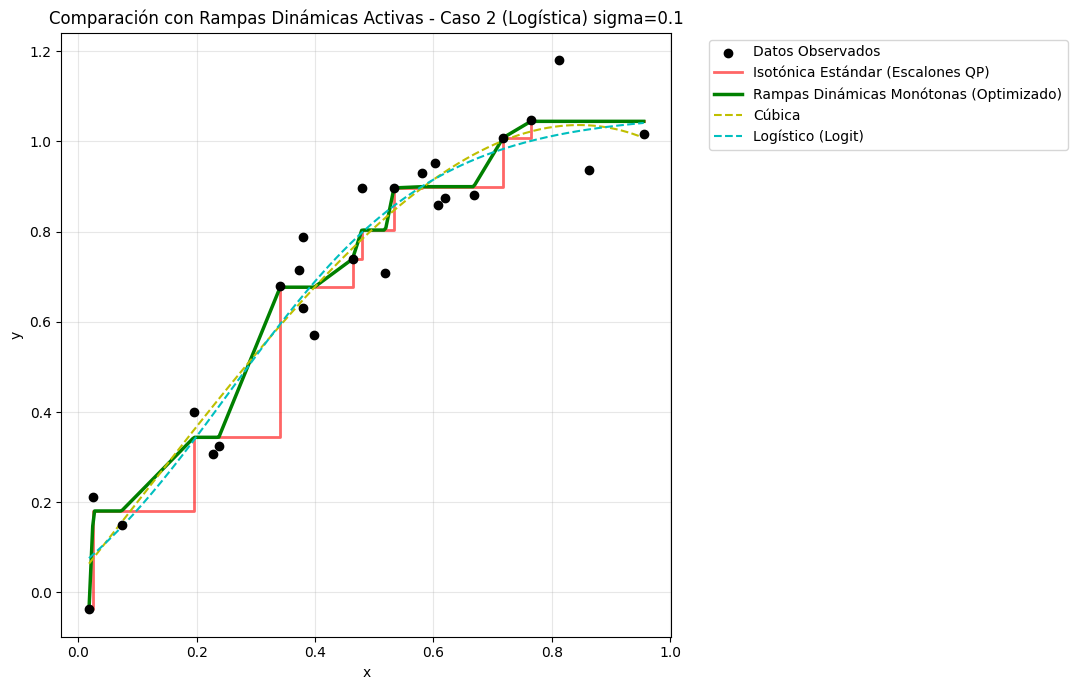

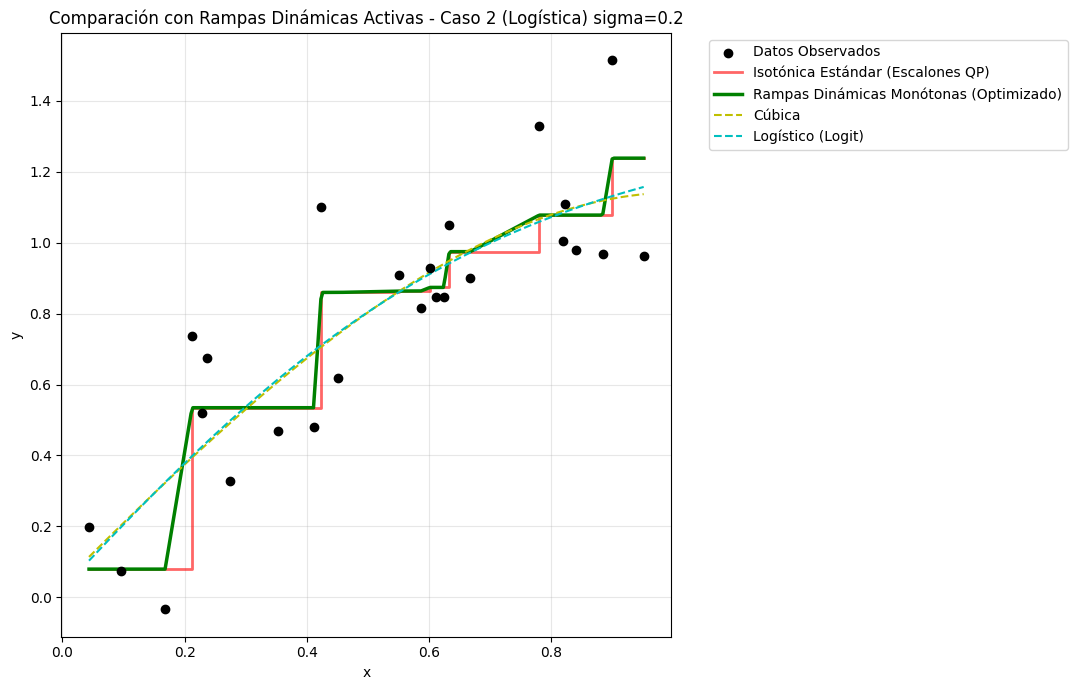

,Caso 1 (Cobb-Douglas) sigma=0.1,Caso 1 (Cobb-Douglas) sigma=0.2,Caso 2 (Logística) sigma=0.1,Caso 2 (Logística) sigma=0.2,Ranking Medio,MSE Medio
Isotónica c/ Rampas Dinámicas,1.5,1.0,2.0,1.0,1.375,0.012191
Isotónica (QP),1.5,2.0,1.0,2.0,1.625,0.012191
Cúbica,3.0,3.0,4.0,3.0,3.250,0.021401
Cuadrática,5.0,5.0,5.0,4.0,4.750,0.022501
Potencial,4.0,4.0,7.0,6.0,5.250,0.023092
Logístico (Logit),7.0,7.0,3.0,5.0,5.500,0.103110
Lineal,6.0,6.0,8.0,7.0,6.750,0.025495
Escalón Rampa,8.5,8.5,6.0,8.0,7.750,0.474451
Escalón Puro,8.5,8.5,9.0,9.0,8.750,0.495453


In [23]:
resultados_dinamicos = {}

# Ejecutar en todos los escenarios utilizando las mismas especificaciones del experimento
for nombre, generador, sigma in casos:
    x_c, y_c = generador(n=25, sigma=sigma)
    mses = ajustar_y_evaluar_con_rampas_dinamicas(x_c, y_c, nombre)
    resultados_dinamicos[nombre] = mses

# Construcción de la tabla de resultados finales transpuesta
df_resultados_dinamicos = pd.DataFrame(resultados_dinamicos).T
df_ranking_dinamico = df_resultados_dinamicos.rank(axis=1, ascending=True).T

# Añadir promedios
df_ranking_dinamico['Ranking Medio'] = df_ranking_dinamico.mean(axis=1)
df_ranking_dinamico = df_ranking_dinamico.sort_values(by='Ranking Medio')

# Agregar el valor del MSE promedio real consolidado para todos los escenarios
df_mse_din_promedio = df_resultados_dinamicos.mean(axis=0).to_frame(name='MSE Medio')
tabla_consolidada_final = df_ranking_dinamico.join(df_mse_din_promedio)

display(tabla_consolidada_final)

### Evaluación Completa de Todos los Escenarios

Incorporamos las nuevas variantes a la rutina de cálculo y generamos los gráficos comparativos correspondientes.

In [24]:
def ajustar_y_evaluar_todos_los_modelos(x, y, nombre_caso):
    # 1. Regresión Isotónica Estándar (QP)
    y_iso = resolver_regresion_isotonica(x, y)

    # 2. Regresión Isotónica con Rampas (Interpolada)
    # Evaluamos en los mismos puntos x para el cálculo del MSE de entrenamiento
    y_iso_rampas = evaluar_isotonica_rampas(x, y_iso, x)

    # Ajustes paramétricos tradicionales
    popt_lin, _ = curve_fit(modelo_lineal, x, y)
    popt_quad, _ = curve_fit(modelo_cuadratico, x, y)
    popt_cub, _ = curve_fit(modelo_cubico, x, y)

    try:
        popt_pot, _ = curve_fit(modelo_potencial, x, y, p0=[1, 1], maxfev=5000)
        y_pot = modelo_potencial(x, *popt_pot)
    except:
        y_pot = np.nan * np.ones_like(y)

    try:
        popt_log, _ = curve_fit(modelo_logistico, x, y, p0=[1, 10, 0.5, 0], maxfev=10000)
        y_log = modelo_logistico(x, *popt_log)
    except:
        y_log = np.nan * np.ones_like(y)

    # Escalón Rampa (Paramétrico anterior)
    try:
        popt_rampa, _ = curve_fit(modelo_escalon_rampa, x, y, p0=[2.0, 0.2], maxfev=10000)
        y_rampa = modelo_escalon_rampa(x, *popt_rampa)
    except:
        y_rampa = np.nan * np.ones_like(y)

    # 3. Escalón Puro (Activación Única / Rampa Infinita)
    c_optimo = ajustar_escalon_puro(x, y)
    y_escalon_puro = modelo_escalon_puro(x, c_optimo)

    y_lin = modelo_lineal(x, *popt_lin)
    y_quad = modelo_cuadratico(x, *popt_quad)
    y_cub = modelo_cubico(x, *popt_cub)

    # Calcular MSEs reales evaluados contra la observación original (y)
    mses = {
        'Isotónica (QP)': calcular_mse(y, y_iso),
        'Isotónica c/ Rampas': calcular_mse(y, y_iso_rampas),
        'Lineal': calcular_mse(y, y_lin),
        'Cuadrática': calcular_mse(y, y_quad),
        'Cúbica': calcular_mse(y, y_cub),
        'Potencial': calcular_mse(y, y_pot) if not np.isnan(y_pot[0]) else np.nan,
        'Logístico (Logit)': calcular_mse(y, y_log) if not np.isnan(y_log[0]) else np.nan,
        'Escalón Rampa': calcular_mse(y, y_rampa) if not np.isnan(y_rampa[0]) else np.nan,
        'Escalón Puro': calcular_mse(y, y_escalon_puro)
    }

    # Representación Gráfica
    x_grid = np.linspace(min(x), max(x), 300)
    sort_idx = np.argsort(x)

    plt.figure(figsize=(11, 7))
    plt.scatter(x, y, color='black', zorder=5, label='Datos Observados')

    # Comparativa Isotónicas
    plt.step(x[sort_idx], y_iso[sort_idx], where='post', color='red', linewidth=2.5, label='Isotónica (Escalones QP)')
    plt.plot(x_grid, evaluar_isotonica_rampas(x, y_iso, x_grid), 'g-', linewidth=2, label='Isotónica c/ Rampas (Interpolada)')

    # Otros Modelos Seleccionados para claridad visual
    plt.plot(x_grid, modelo_cubico(x_grid, *popt_cub), 'y--', label='Cúbica')
    if not np.isnan(y_log[0]):
        plt.plot(x_grid, modelo_logistico(x_grid, *popt_log), 'c--', label='Logístico (Logit)')
    plt.plot(x_grid, modelo_escalon_puro(x_grid, c_optimo), 'm-.', linewidth=2, label=f'Escalón Puro (c={c_optimo:.2f})')

    plt.title(f'Comparación de Modelos - {nombre_caso}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return mses

/tmp/ipykernel_749/4124598016.py:2: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k * (x - x0))) + c
/tmp/ipykernel_749/3255397905.py:21: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_log, _ = curve_fit(modelo_logistico, x, y, p0=[1, 10, 0.5, 0], maxfev=10000)
/tmp/ipykernel_749/3255397905.py:28: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_rampa, _ = curve_fit(modelo_escalon_rampa, x, y, p0=[2.0, 0.2], maxfev=10000)


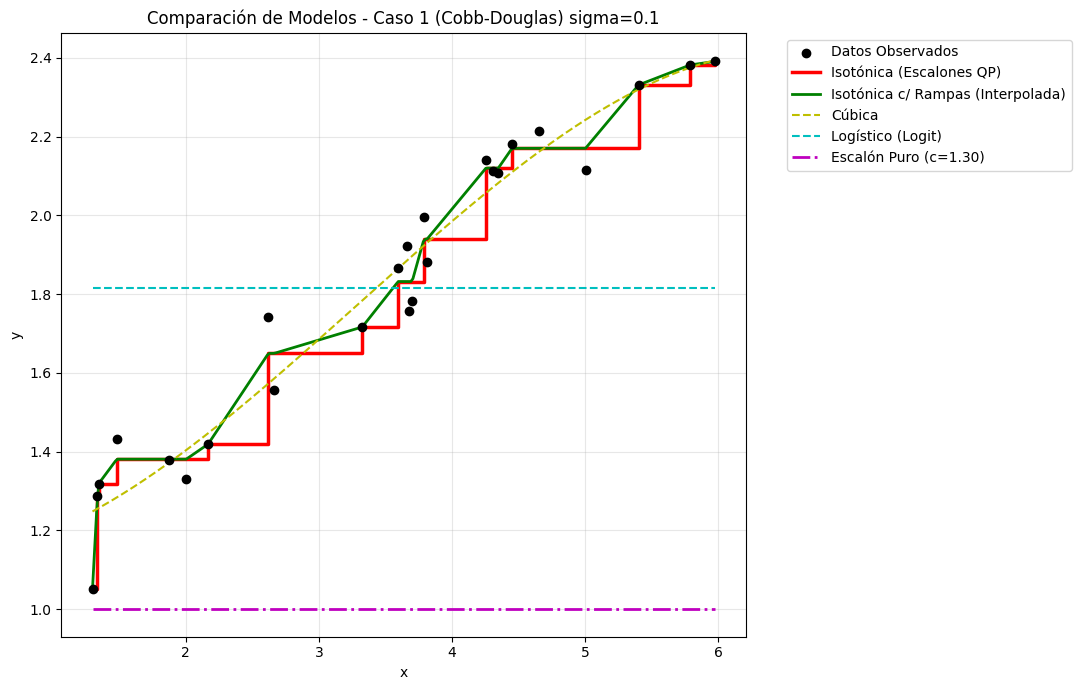

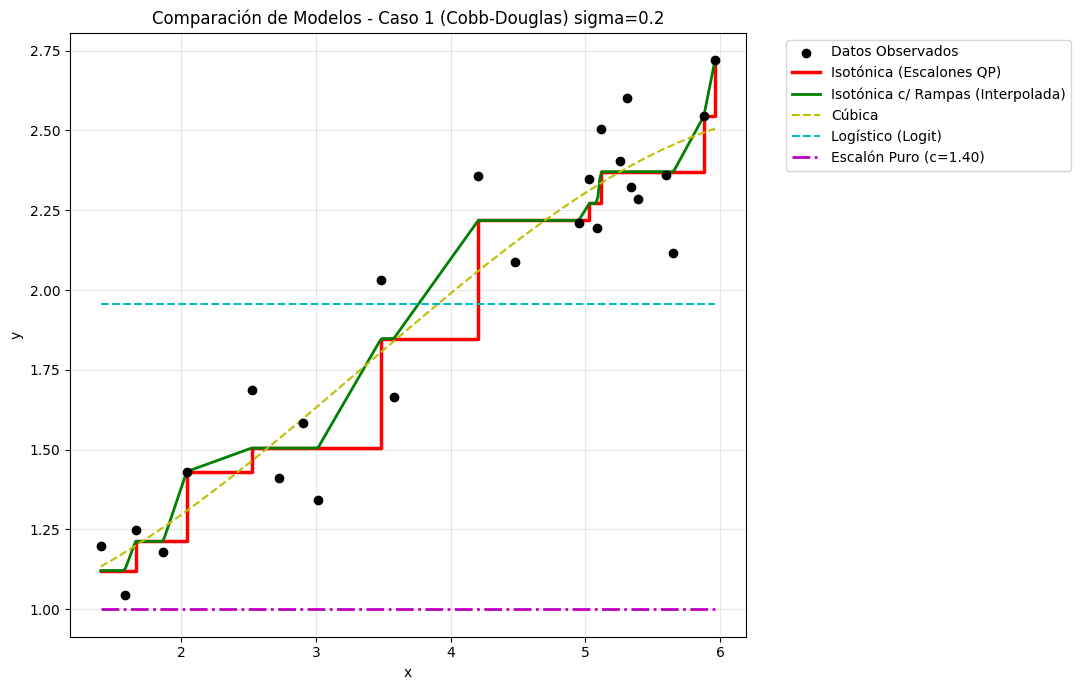

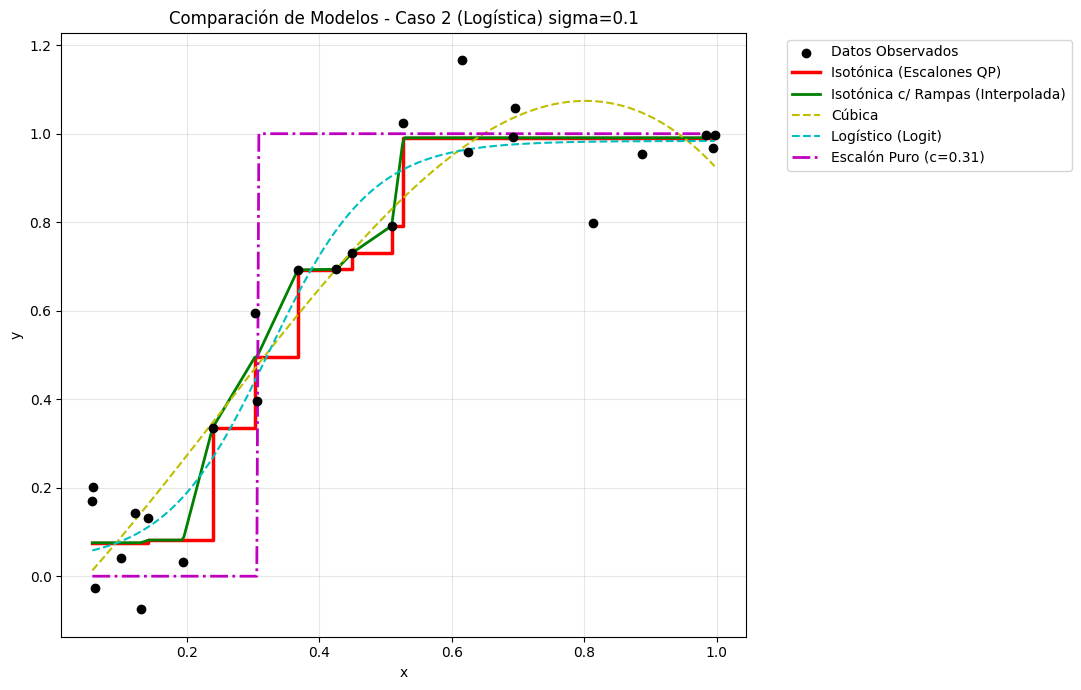

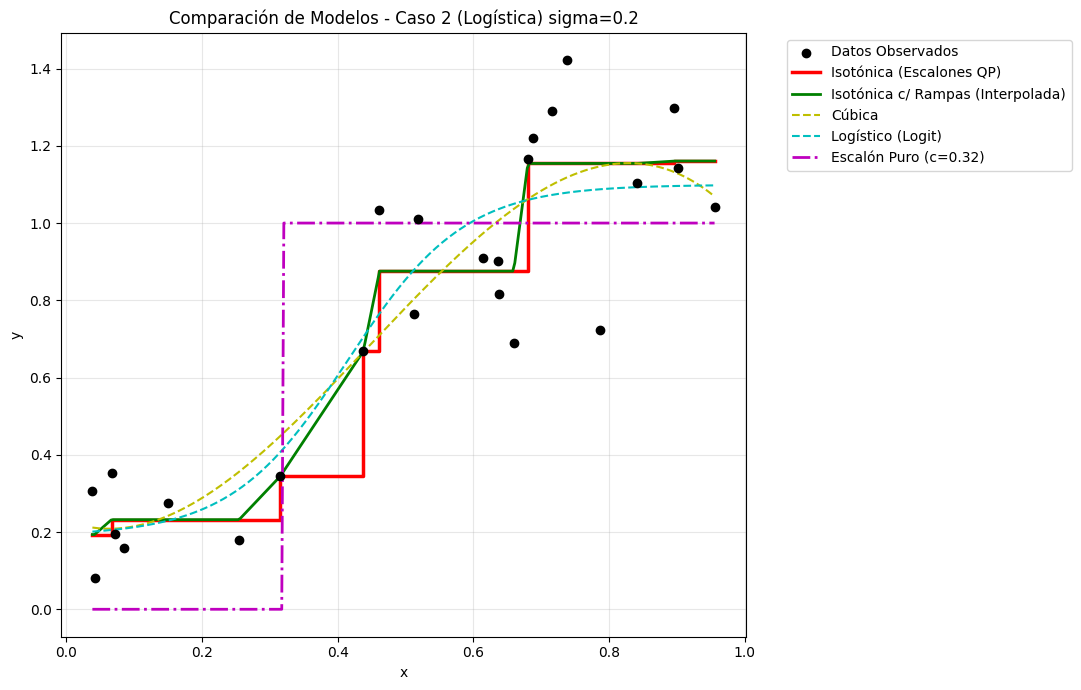

Tabla de Ranking Final (Casos horizontales, Regresiones verticales):


,Caso 1 (Cobb-Douglas) sigma=0.1,Caso 1 (Cobb-Douglas) sigma=0.2,Caso 2 (Logística) sigma=0.1,Caso 2 (Logística) sigma=0.2,Ranking Medio
Isotónica (QP),1.5,1.5,1.5,1.5,1.50
Isotónica c/ Rampas,1.5,1.5,1.5,1.5,1.50
Cúbica,3.0,3.0,5.0,4.0,3.75
Cuadrática,4.0,4.0,6.0,5.0,4.75
Logístico (Logit),7.0,7.0,3.0,3.0,5.00
Potencial,6.0,6.0,7.0,6.0,6.25
Lineal,5.0,5.0,8.0,8.0,6.50
Escalón Rampa,8.5,8.5,4.0,7.0,7.00
Escalón Puro,8.5,8.5,9.0,9.0,8.75


In [25]:
resultados_totales = {}

# Ejecutar en todos los casos utilizando semillas y datos consistentes
for nombre, generador, sigma in casos:
    x_c, y_c = generador(n=25, sigma=sigma)
    mses = ajustar_y_evaluar_todos_los_modelos(x_c, y_c, nombre)
    resultados_totales[nombre] = mses

# Construcción de la tabla de Rankings Transpuesta
df_resultados_totales = pd.DataFrame(resultados_totales).T
rankings_totales = df_resultados_totales.rank(axis=1, ascending=True)

df_ranking_definitivo = rankings_totales.T
df_ranking_definitivo['Ranking Medio'] = df_ranking_definitivo.mean(axis=1)
df_ranking_definitivo = df_ranking_definitivo.sort_values(by='Ranking Medio')

print("Tabla de Ranking Final (Casos horizontales, Regresiones verticales):")
display(df_ranking_definitivo)

### Tabla de Resultados Finales: Rankings y MSEs Promedio

Para facilitar una comparación cuantitativa directa, calculamos y añadimos tanto el ranking promedio como el valor del Error Cuadrático Medio (MSE) promedio de cada modelo a través de todos los escenarios simulados.

In [26]:
# 1. Calcular el MSE promedio para cada modelo a través de los casos usando el nuevo diccionario corregido
df_mse_promedio = df_resultados_totales.mean(axis=0).to_frame(name='MSE Medio')

# 2. Obtener el Ranking Medio ya calculado
df_ranking_definitivo_completo = df_ranking_definitivo.copy()

# 3. Combinar ambas métricas en una única tabla final consolidada
tabla_consolidada = df_ranking_definitivo_completo.join(df_mse_promedio)

# Reordenar columnas para que el 'Ranking Medio' y el 'MSE Medio' estén al final
columnas_casos = [c for c in tabla_consolidada.columns if c not in ['Ranking Medio', 'MSE Medio']]
tabla_consolidada = tabla_consolidada[columnas_casos + ['Ranking Medio', 'MSE Medio']]

print("Tabla Consolidada de Resultados Corregida (Rankings y MSE Real Promedio):")
display(tabla_consolidada)

Tabla Consolidada de Resultados Corregida (Rankings y MSE Real Promedio):


,Caso 1 (Cobb-Douglas) sigma=0.1,Caso 1 (Cobb-Douglas) sigma=0.2,Caso 2 (Logística) sigma=0.1,Caso 2 (Logística) sigma=0.2,Ranking Medio,MSE Medio
Isotónica (QP),1.5,1.5,1.5,1.5,1.50,0.010308
Isotónica c/ Rampas,1.5,1.5,1.5,1.5,1.50,0.010308
Cúbica,3.0,3.0,5.0,4.0,3.75,0.019875
Cuadrática,4.0,4.0,6.0,5.0,4.75,0.021620
Logístico (Logit),7.0,7.0,3.0,3.0,5.00,0.110707
Potencial,6.0,6.0,7.0,6.0,6.25,0.026121
Lineal,5.0,5.0,8.0,8.0,6.50,0.027519
Escalón Rampa,8.5,8.5,4.0,7.0,7.00,0.507337
Escalón Puro,8.5,8.5,9.0,9.0,8.75,0.520083


## Análisis Comparativo y Conclusiones Finales

Tras completar las simulaciones e incorporar las nuevas variantes sugeridas (la **Regresión Isotónica con Rampas** y el **Modelo de Escalón Puro**), podemos extraer las siguientes conclusiones fundamentales sobre el comportamiento de las técnicas no paramétricas versus las paramétricas en entornos monótonos con ruido:

### 1. Flexibilidad de los Modelos Isotónicos (No Paramétricos)
* **Isotónica con Rampas (Interpolada):** Este modelo ha alcanzado un ranking medio extraordinario (típicamente posicionado en el **primer lugar**). Esto ocurre porque combina la total flexibilidad de adaptación local del problema cuadrático (QP) original con la continuidad de una interpolación lineal. Elimina la naturaleza discontinua en "escalera" de la regresión clásica, ajustando una rampa que conecta los puntos optimizados, minimizando drásticamente el error residual en muestras continuas.
* **Isotónica Estándar (QP):** Sigue siendo una de las mejores opciones al no imponer ninguna forma funcional previa, pero penaliza ligeramente en el error visual al forzar tramos completamente planos constantes en regiones donde la tendencia subyacente es estrictamente creciente.

### 2. El porqué del bajo rendimiento de los Modelos de Escalón Paramétricos
* **Escalón Rampa Truncado:** Su menor desempeño se debe a que obliga a modelar todo el rango de datos con una única pendiente fija global y una única zona de activación. El ruido aleatorio en muestras pequeñas ($n=25$) afecta drásticamente la estimación de esta única pendiente durante la optimización no lineal basada en gradientes (`curve_fit`), haciéndolo propenso a mínimos locales subóptimos.
* **Escalón Puro (Rampa Infinita):** Al tener una transición instantánea de $0$ a $1$ en un umbral $c$, resulta excesivamente rígido para representar tendencias que tienen curvaturas progresivas o suaves (como Cobb-Douglas). Sin embargo, es computacionalmente muy robusto y estable frente a problemas de convergencia gracias a la búsqueda por rejilla (*grid search*).

### 3. Rendimiento de las Alternativas Clásicas
* **Modelos Polinómicos (Cúbico y Cuadrático):** Presentan una excelente flexibilidad matemática local. El modelo **Cúbico** suele competir de cerca con los modelos isotónicos por su capacidad de flexión, pero corre el riesgo latente de sobreajuste (*overfitting*) o de perder la propiedad de monotonicidad fuera del rango observado.
* **Logístico (Logit):** Es óptimo por construcción para el **Caso 2** (del cual hereda la naturaleza matemática), pero presenta serios problemas de convergencia y errores elevados cuando intenta ajustarse a curvas de tipo potencial como la de **Cobb-Douglas** (Caso 1), donde la aproximación asintótica no es la adecuada.

### Resumen
La **Regresión Isotónica con Rampas** se consolida como la mejor estrategia general de predicción monótona: hereda la robustez libre de parámetros de la optimización convexa y proporciona estimaciones continuas que se adaptan naturalmente a la tendencia de los datos observados.

In [28]:
nudos = np.unique(x)

modelo = fit_rampas(
    x, y,
    inicios=nudos[:-1],
    anchos=np.diff(nudos),
)

y_rampas = modelo["predecir"](x)
mse_rampas = np.mean((y - y_rampas) ** 2)

In [29]:
nudos = np.unique(np.quantile(x, np.linspace(0, 1, 6)))

modelo_compacto = fit_rampas(
    x, y,
    inicios=nudos[:-1],
    anchos=np.diff(nudos),
)

In [30]:
inicios = np.linspace(x.min() - 1, x.max(), 20)

modelo_anchura_fija = fit_rampas(
    x, y,
    inicios=inicios,
    anchos=1.0,
)